# Phase 11 — KUB Global Baseline Failure Analysis

VAL-only deterministic analysis. UNet++ is the fixed primary model; DeepLabV3+ is the FP comparator. **No training, tuning, ROI experiment, TEST access, or external-data access.**

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd().resolve(); ROOT=ROOT.parent if ROOT.name=='notebooks' else ROOT
T=ROOT/'reports/tables'; F=ROOT/'reports/figures/phase11_kub_failure_analysis'; Q=ROOT/'reports/qualitative/phase11_kub_failure_analysis'
x=pd.read_csv(T/'phase11_kub_failure_analysis_per_image.csv'); c=pd.read_csv(T/'phase11_kub_failure_analysis_per_component.csv'); cut=json.loads((ROOT/'reports/audits/phase11_failure_strata_definitions.json').read_text())
print('Governance PASS: phase4_v2; VAL only; threshold 0.5; TEST NOT ACCESSED')

Governance PASS: phase4_v2; VAL only; threshold 0.5; TEST NOT ACCESSED


## Primary-model rationale and frozen reference

In [2]:
display(pd.read_csv(T/'phase10_kub_model_comparison.csv'))
print('UNet++ fixed as primary from Phase 10; DeepLabV3+ retained for low-FP comparison.')

,model,parameters,best_epoch,epochs_completed,physical_batch,effective_batch,macro_dice,macro_iou,macro_precision,macro_recall,...,full_field_dice,roi_crop_dice,tiny_object_recall,small_object_recall,medium_object_recall,large_object_recall,training_wall_time,mean_epoch_time,peak_gpu_allocated,peak_gpu_reserved
0,U-Net,7762465,47,62,4,4,0.745544,0.631643,0.799446,0.765422,...,0.613015,0.824911,0.753425,0.827586,0.805556,0.944444,4530.025540,73.064928,1723826176,2015363072
1,Attention U-Net,7850709,77,92,4,4,0.753014,0.637711,0.793537,0.774175,...,0.643275,0.818733,0.753425,0.862069,0.805556,0.944444,6472.539551,70.353691,2042458112,2415919104
2,UNet++,9159105,77,92,4,4,0.762494,0.651495,0.822798,0.775599,...,0.652776,0.828201,0.780822,0.862069,0.888889,0.944444,16292.141339,177.088493,5330496000,5997854720
3,DeepLabV3+,40340769,37,52,4,4,0.748787,0.643457,0.783811,0.783367,...,0.561354,0.861035,0.630137,0.827586,0.861111,0.944444,4872.600573,93.703857,2042002944,2246049792


UNet++ fixed as primary from Phase 10; DeepLabV3+ retained for low-FP comparison.


## Primary-model training provenance

UNet++ was trained and selected in Phase 10. Phase 11 performs no model training. These curves are loaded from finalized Phase-10 history for provenance (epochs completed: 92, best epoch: 77, early stopping epoch: 92).

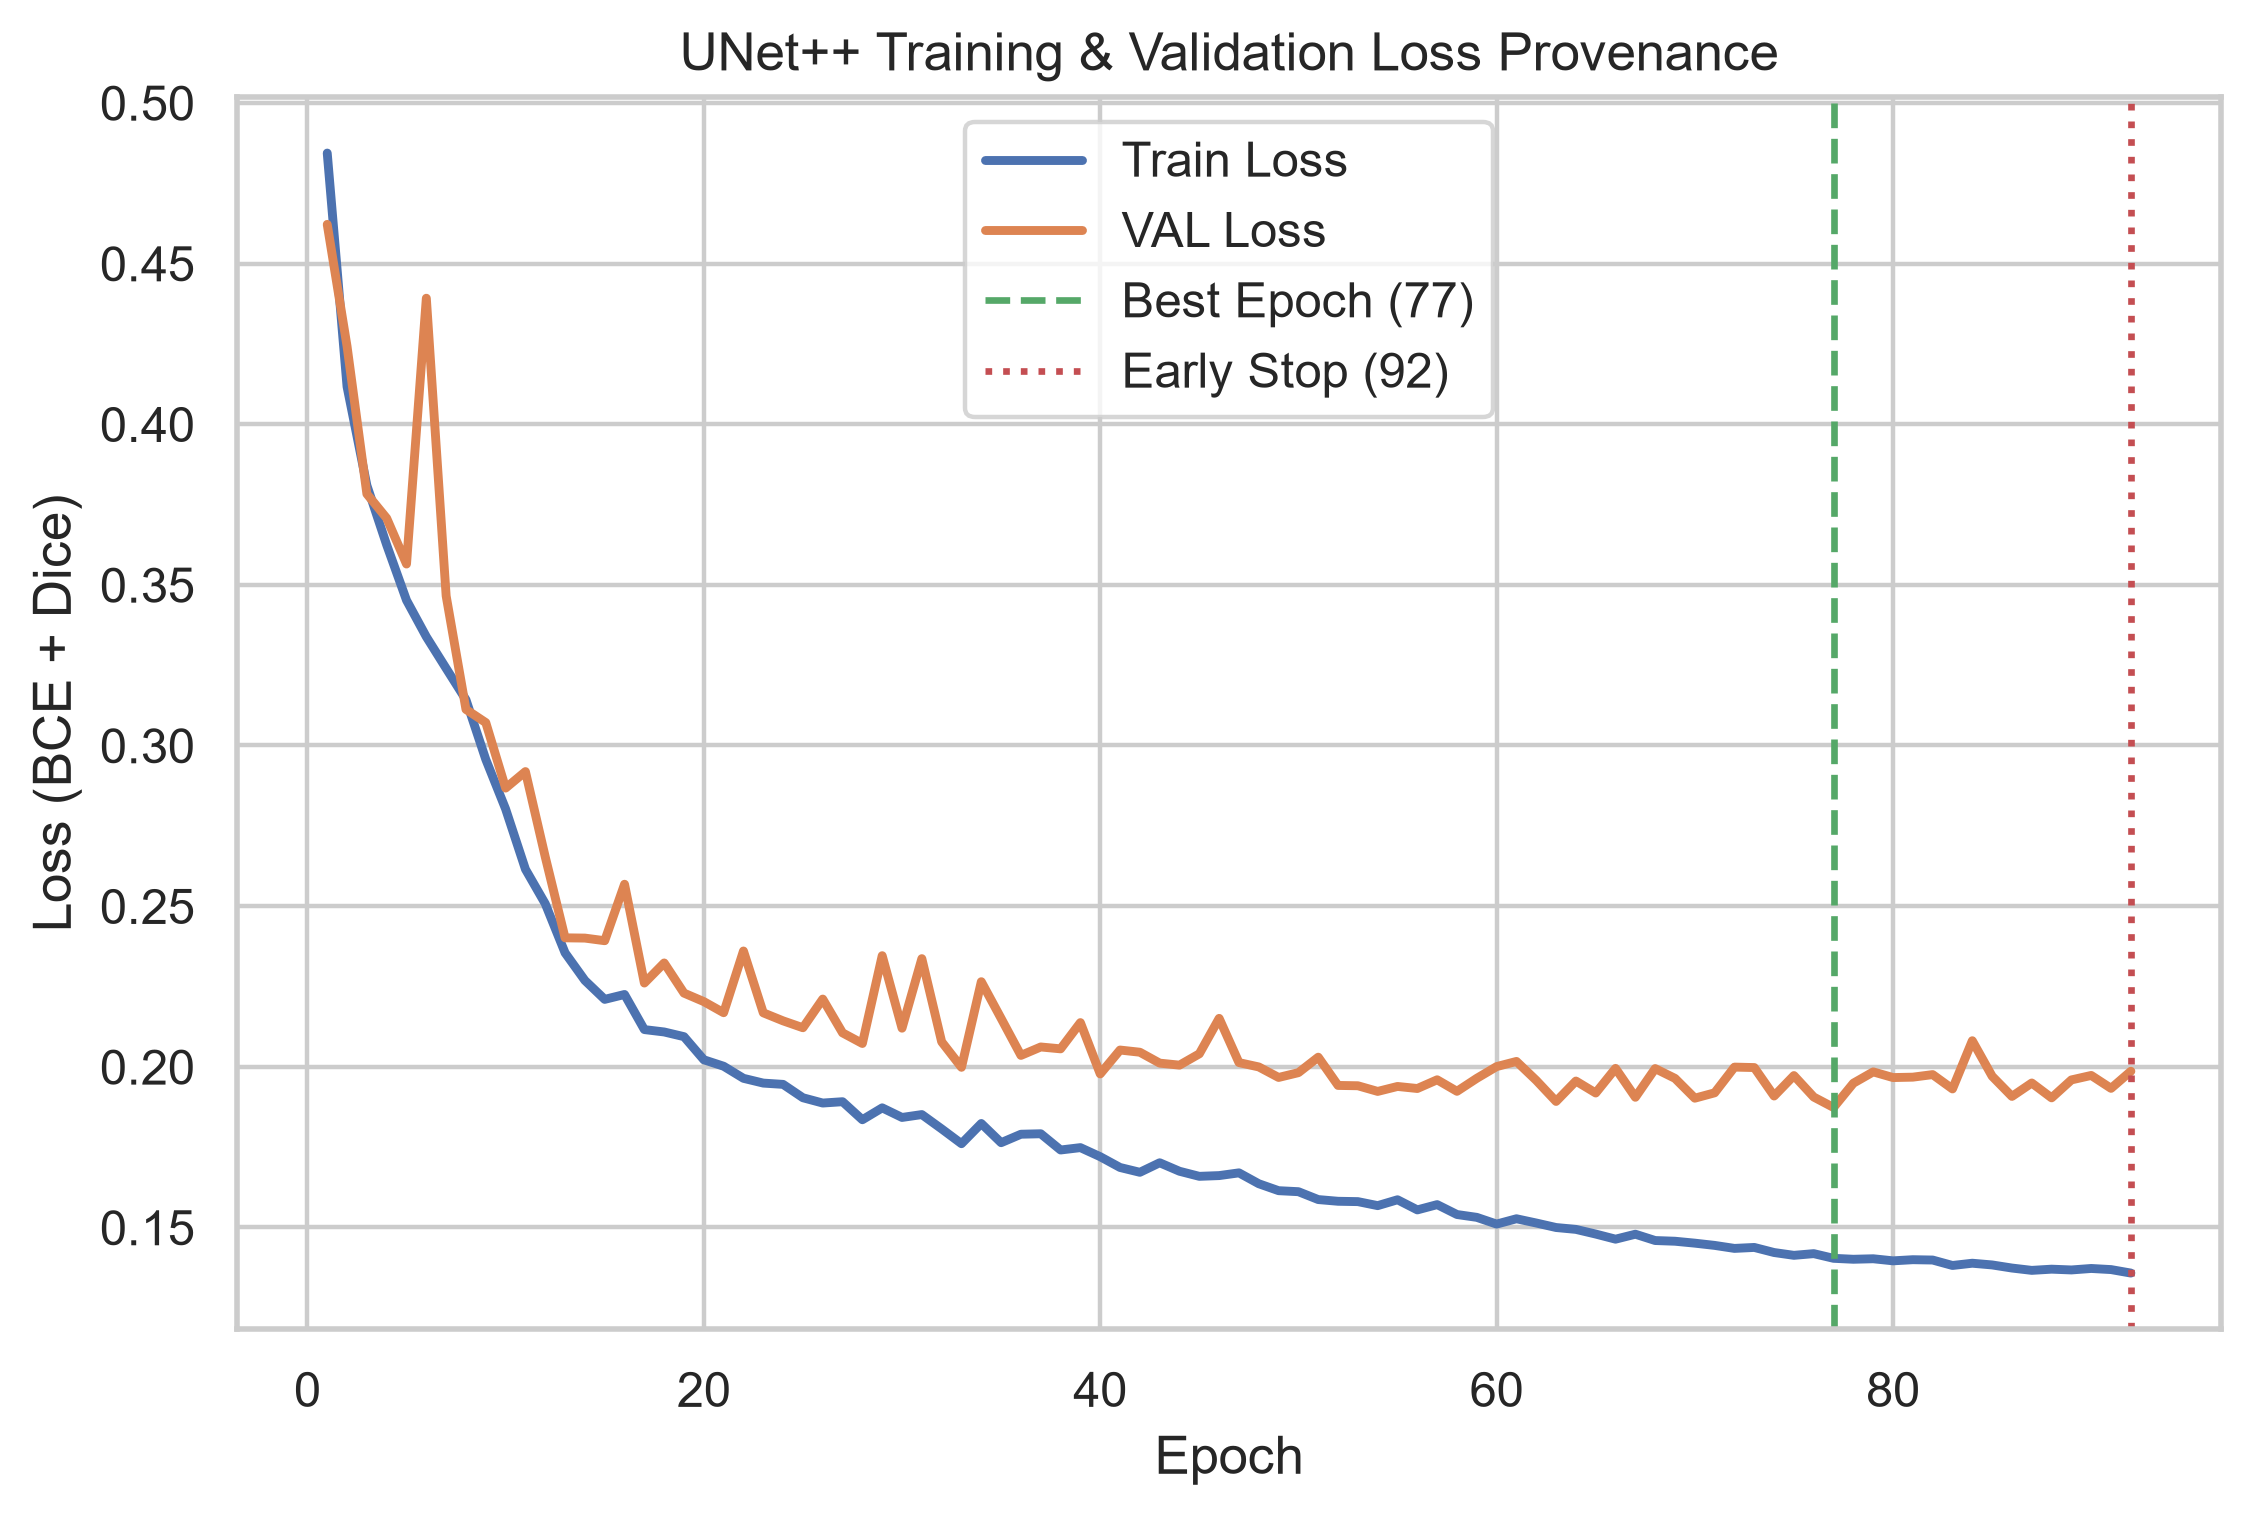

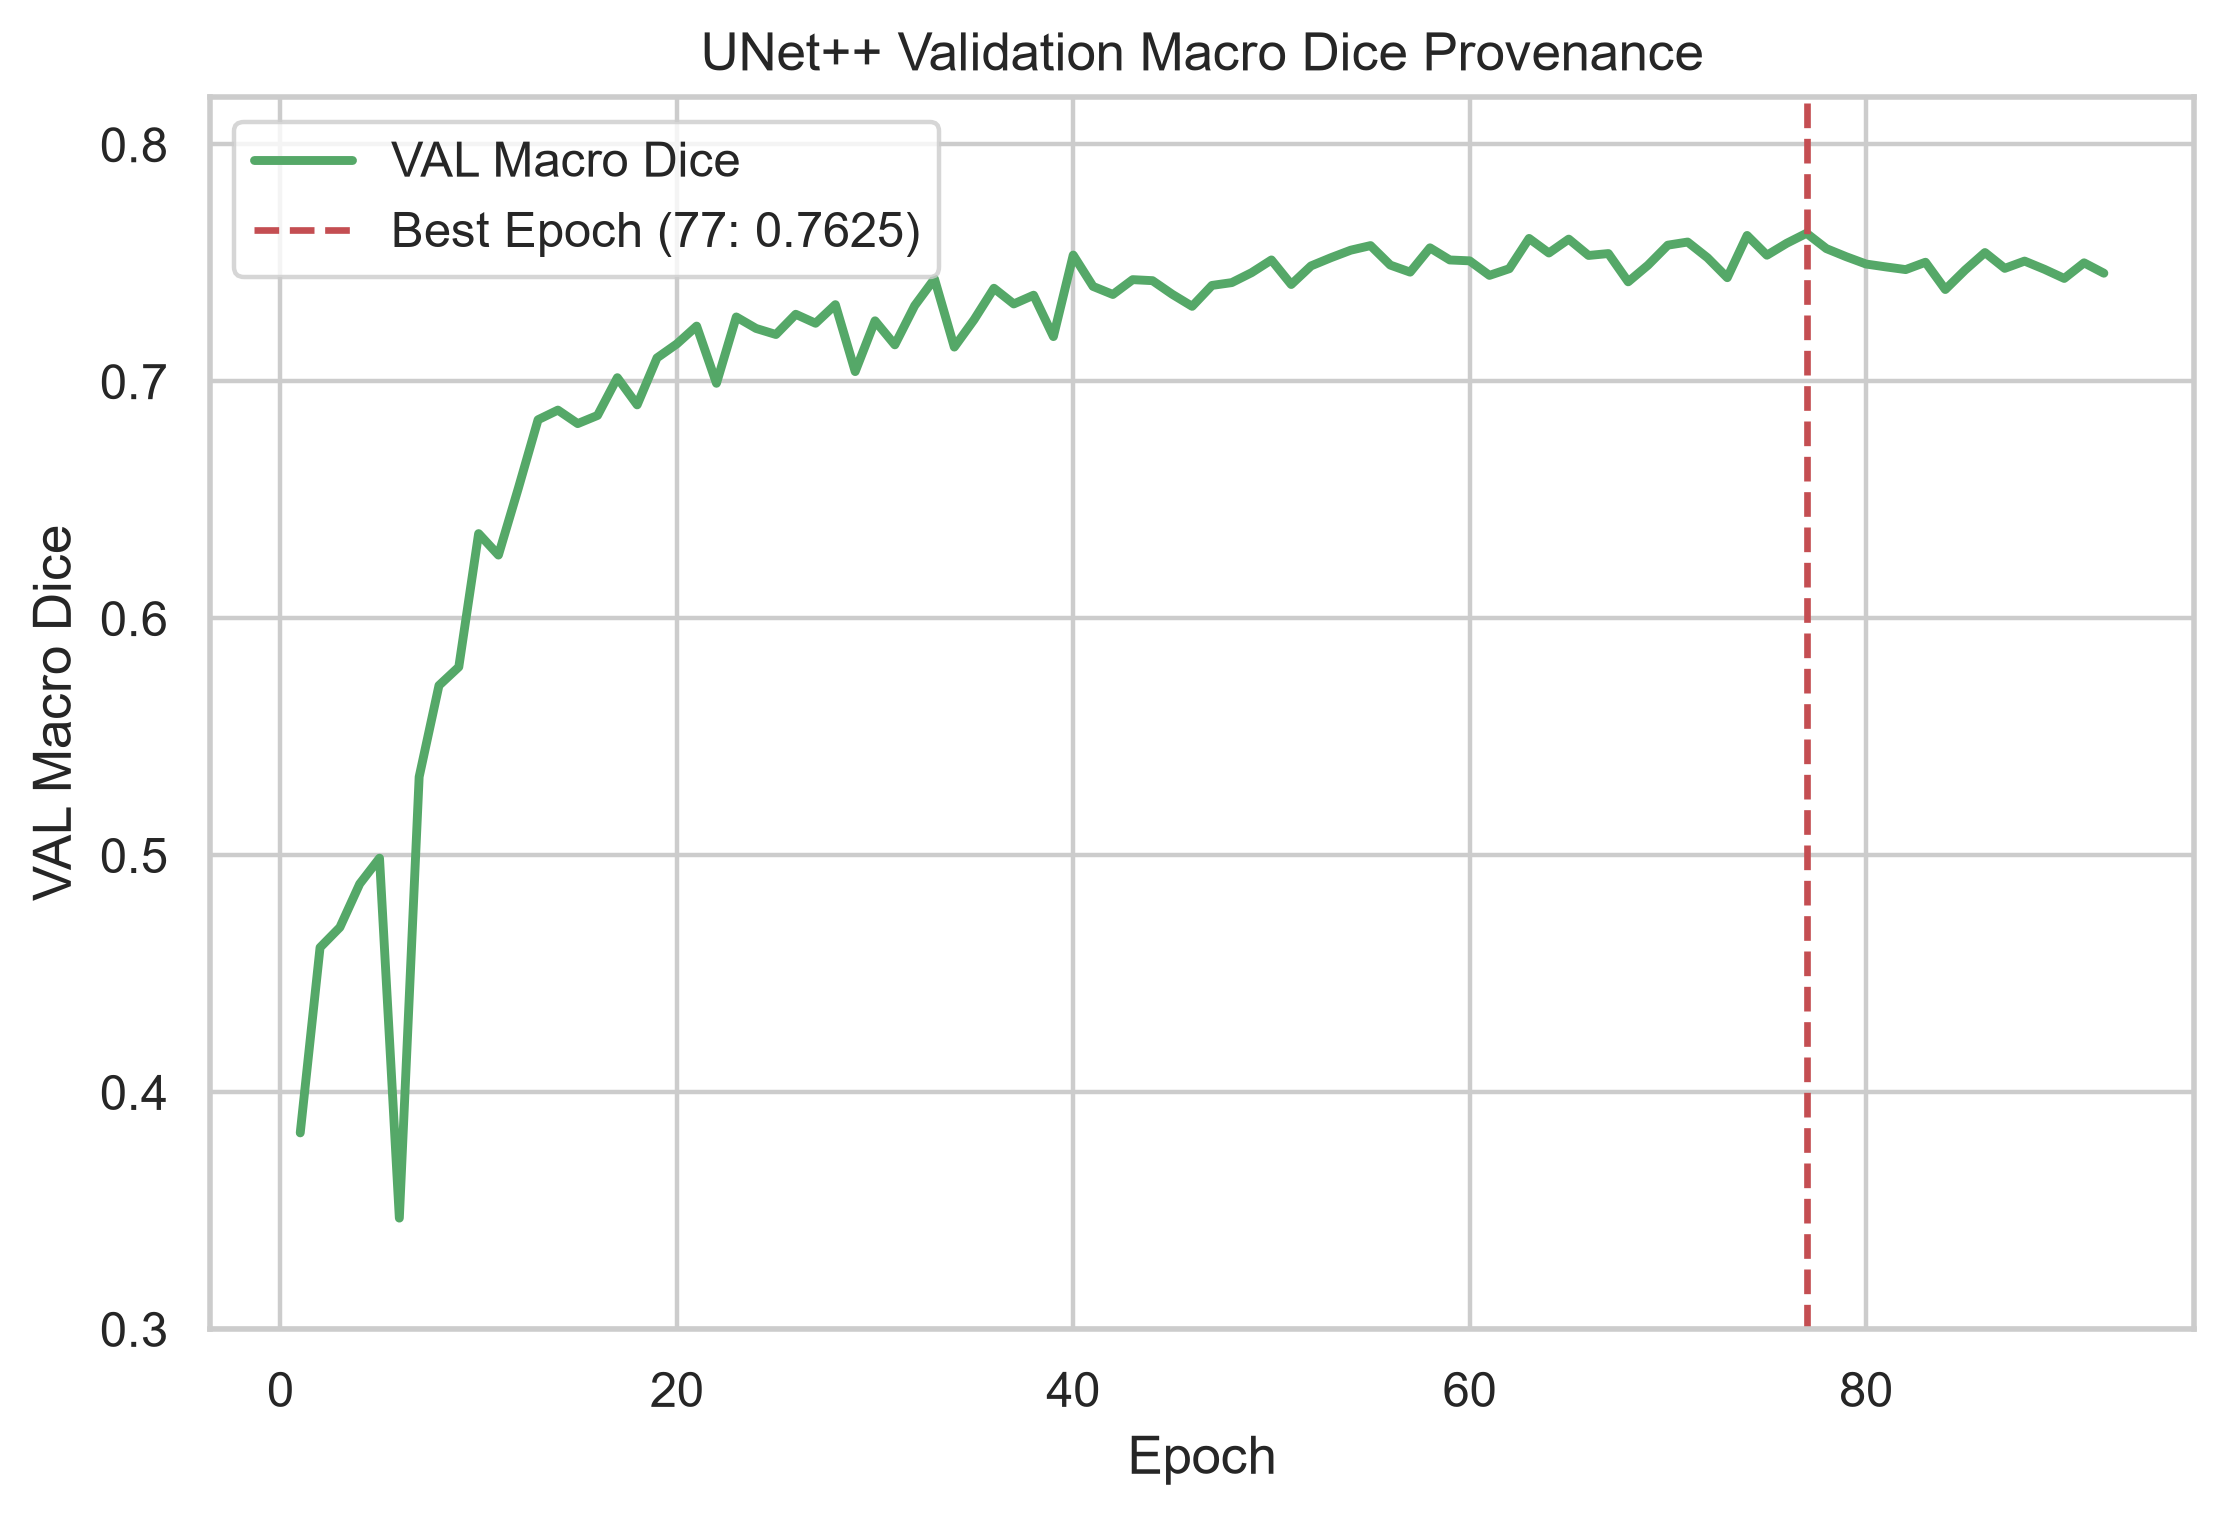

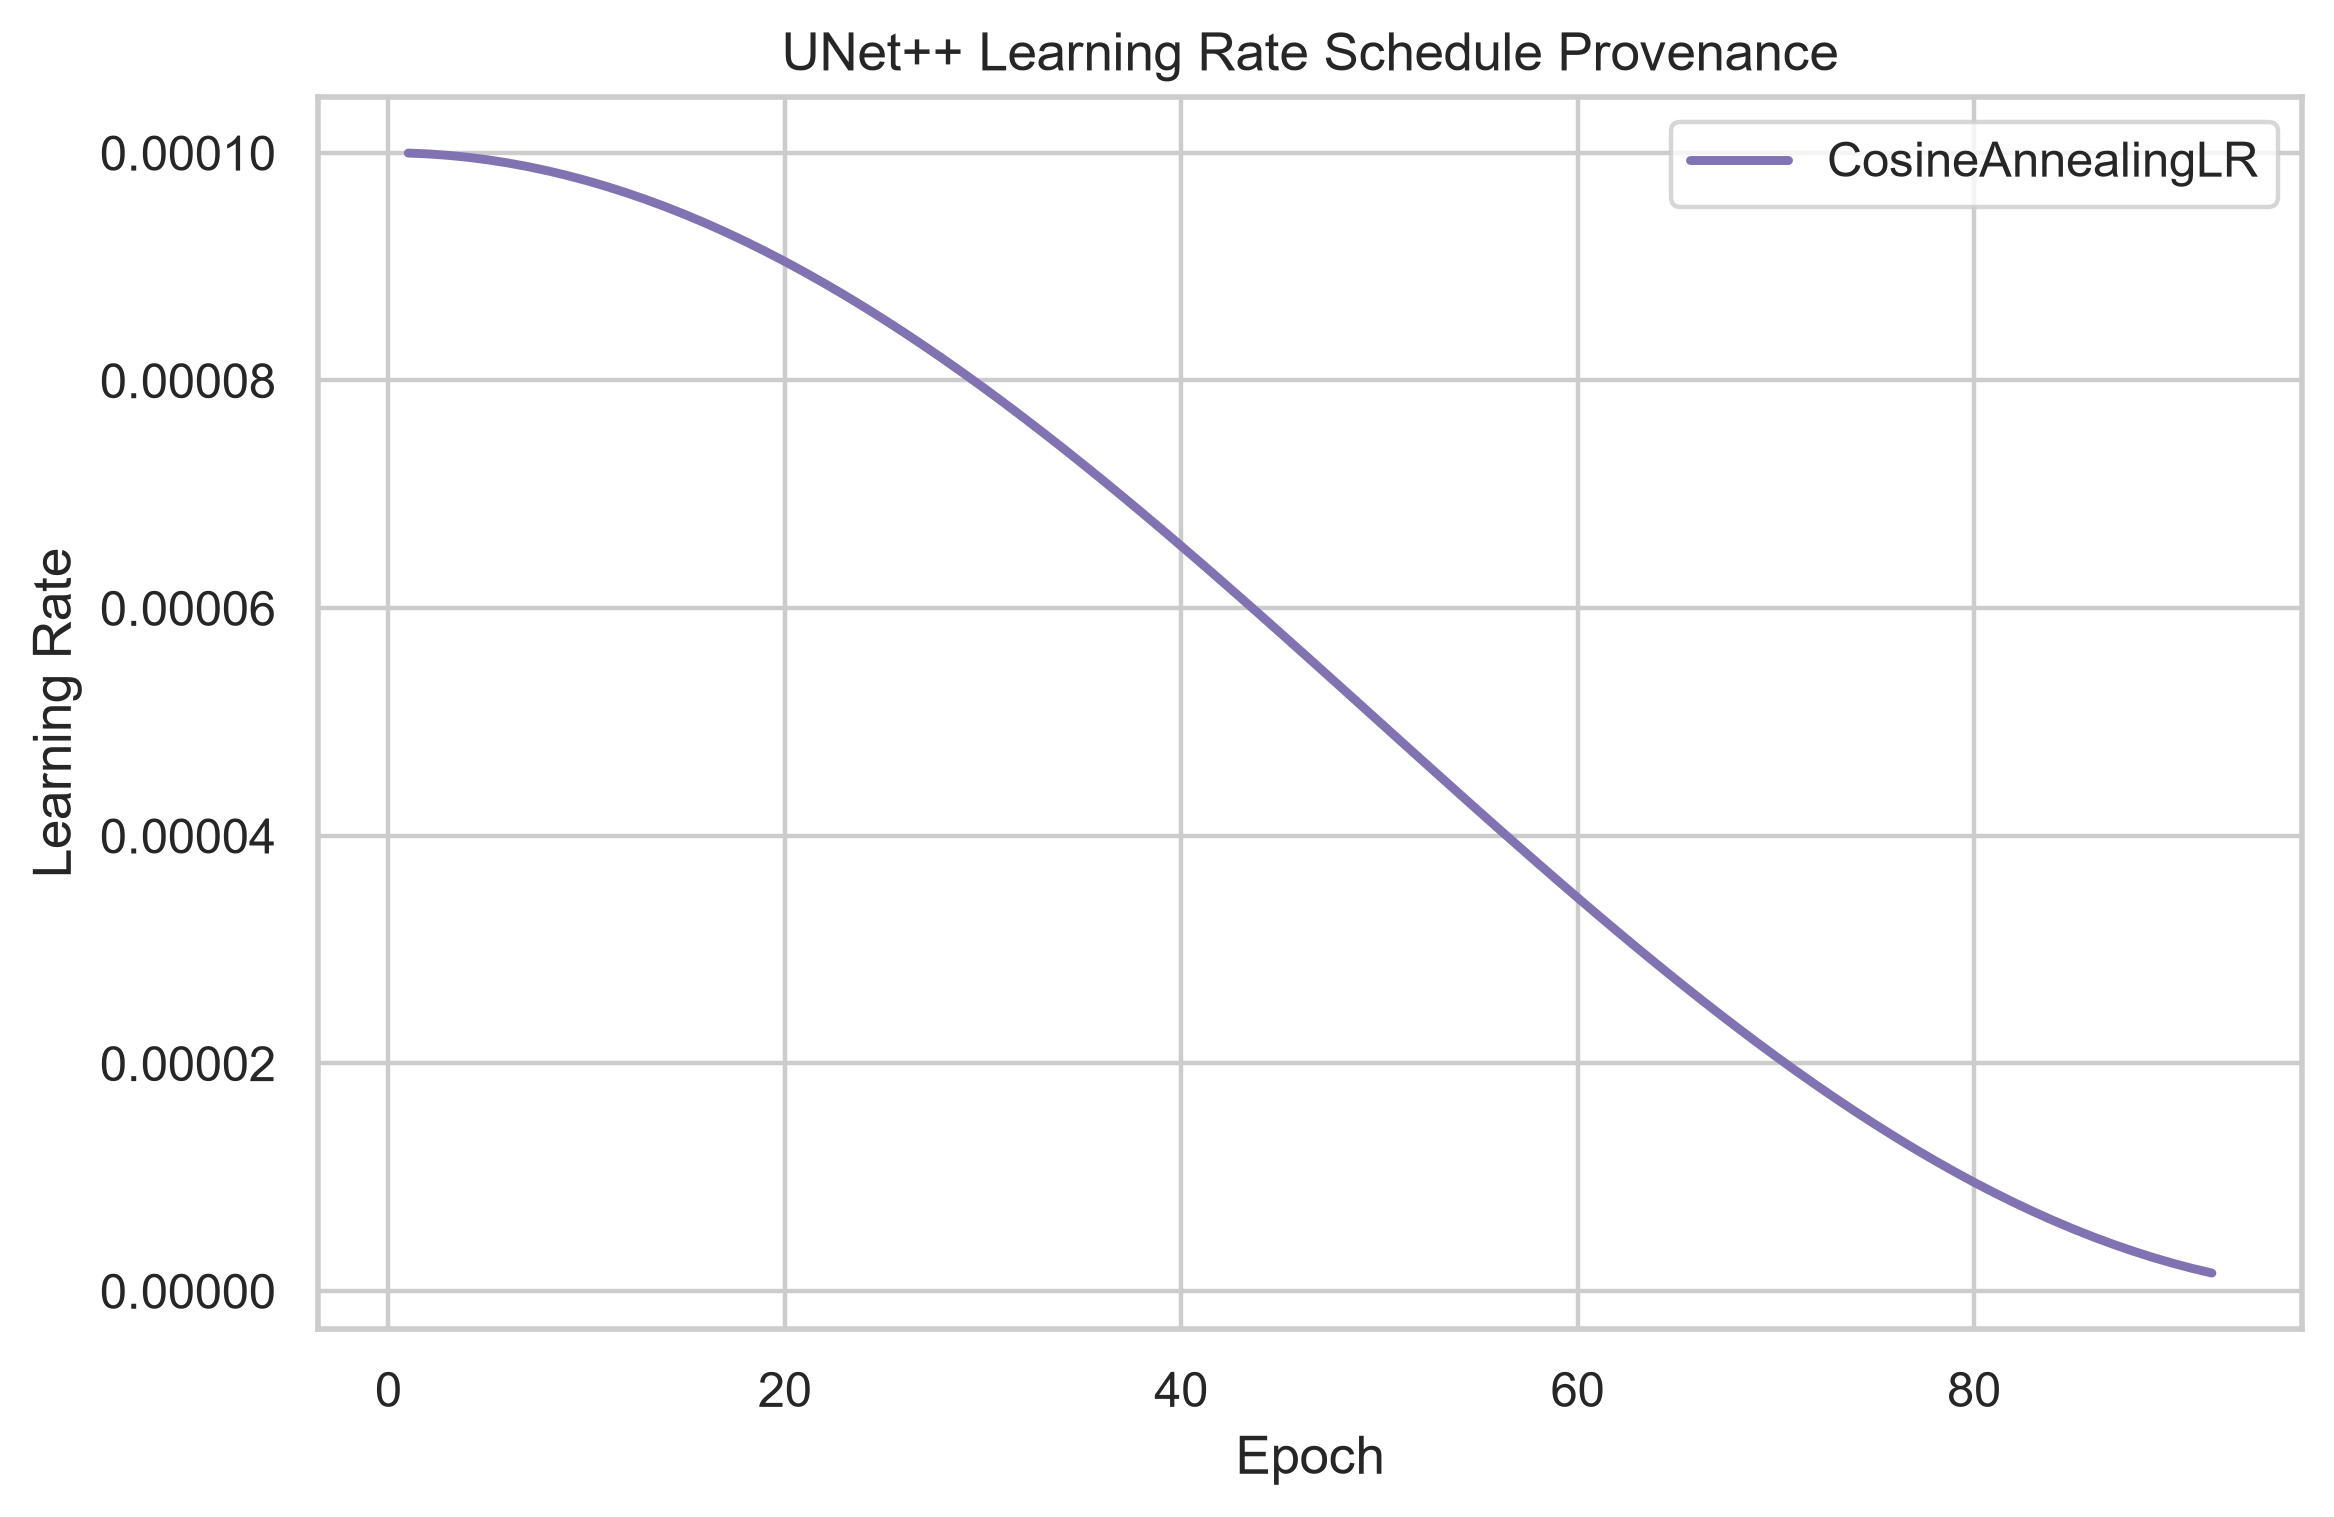

In [3]:
display(Image(filename=str(F/'phase11_unetpp_training_loss_provenance.png'),width=850))
display(Image(filename=str(F/'phase11_unetpp_val_dice_provenance.png'),width=850))
display(Image(filename=str(F/'phase11_unetpp_lr_provenance.png'),width=850))

## FOV failure distributions and foreground scale

,N,Macro_Dice,Macro_IoU,Precision,Recall
FOV,,,,,
FULL_FIELD,106,0.652776,0.537766,0.772448,0.671990
ROI_CROP,177,0.828201,0.719604,0.852952,0.837647


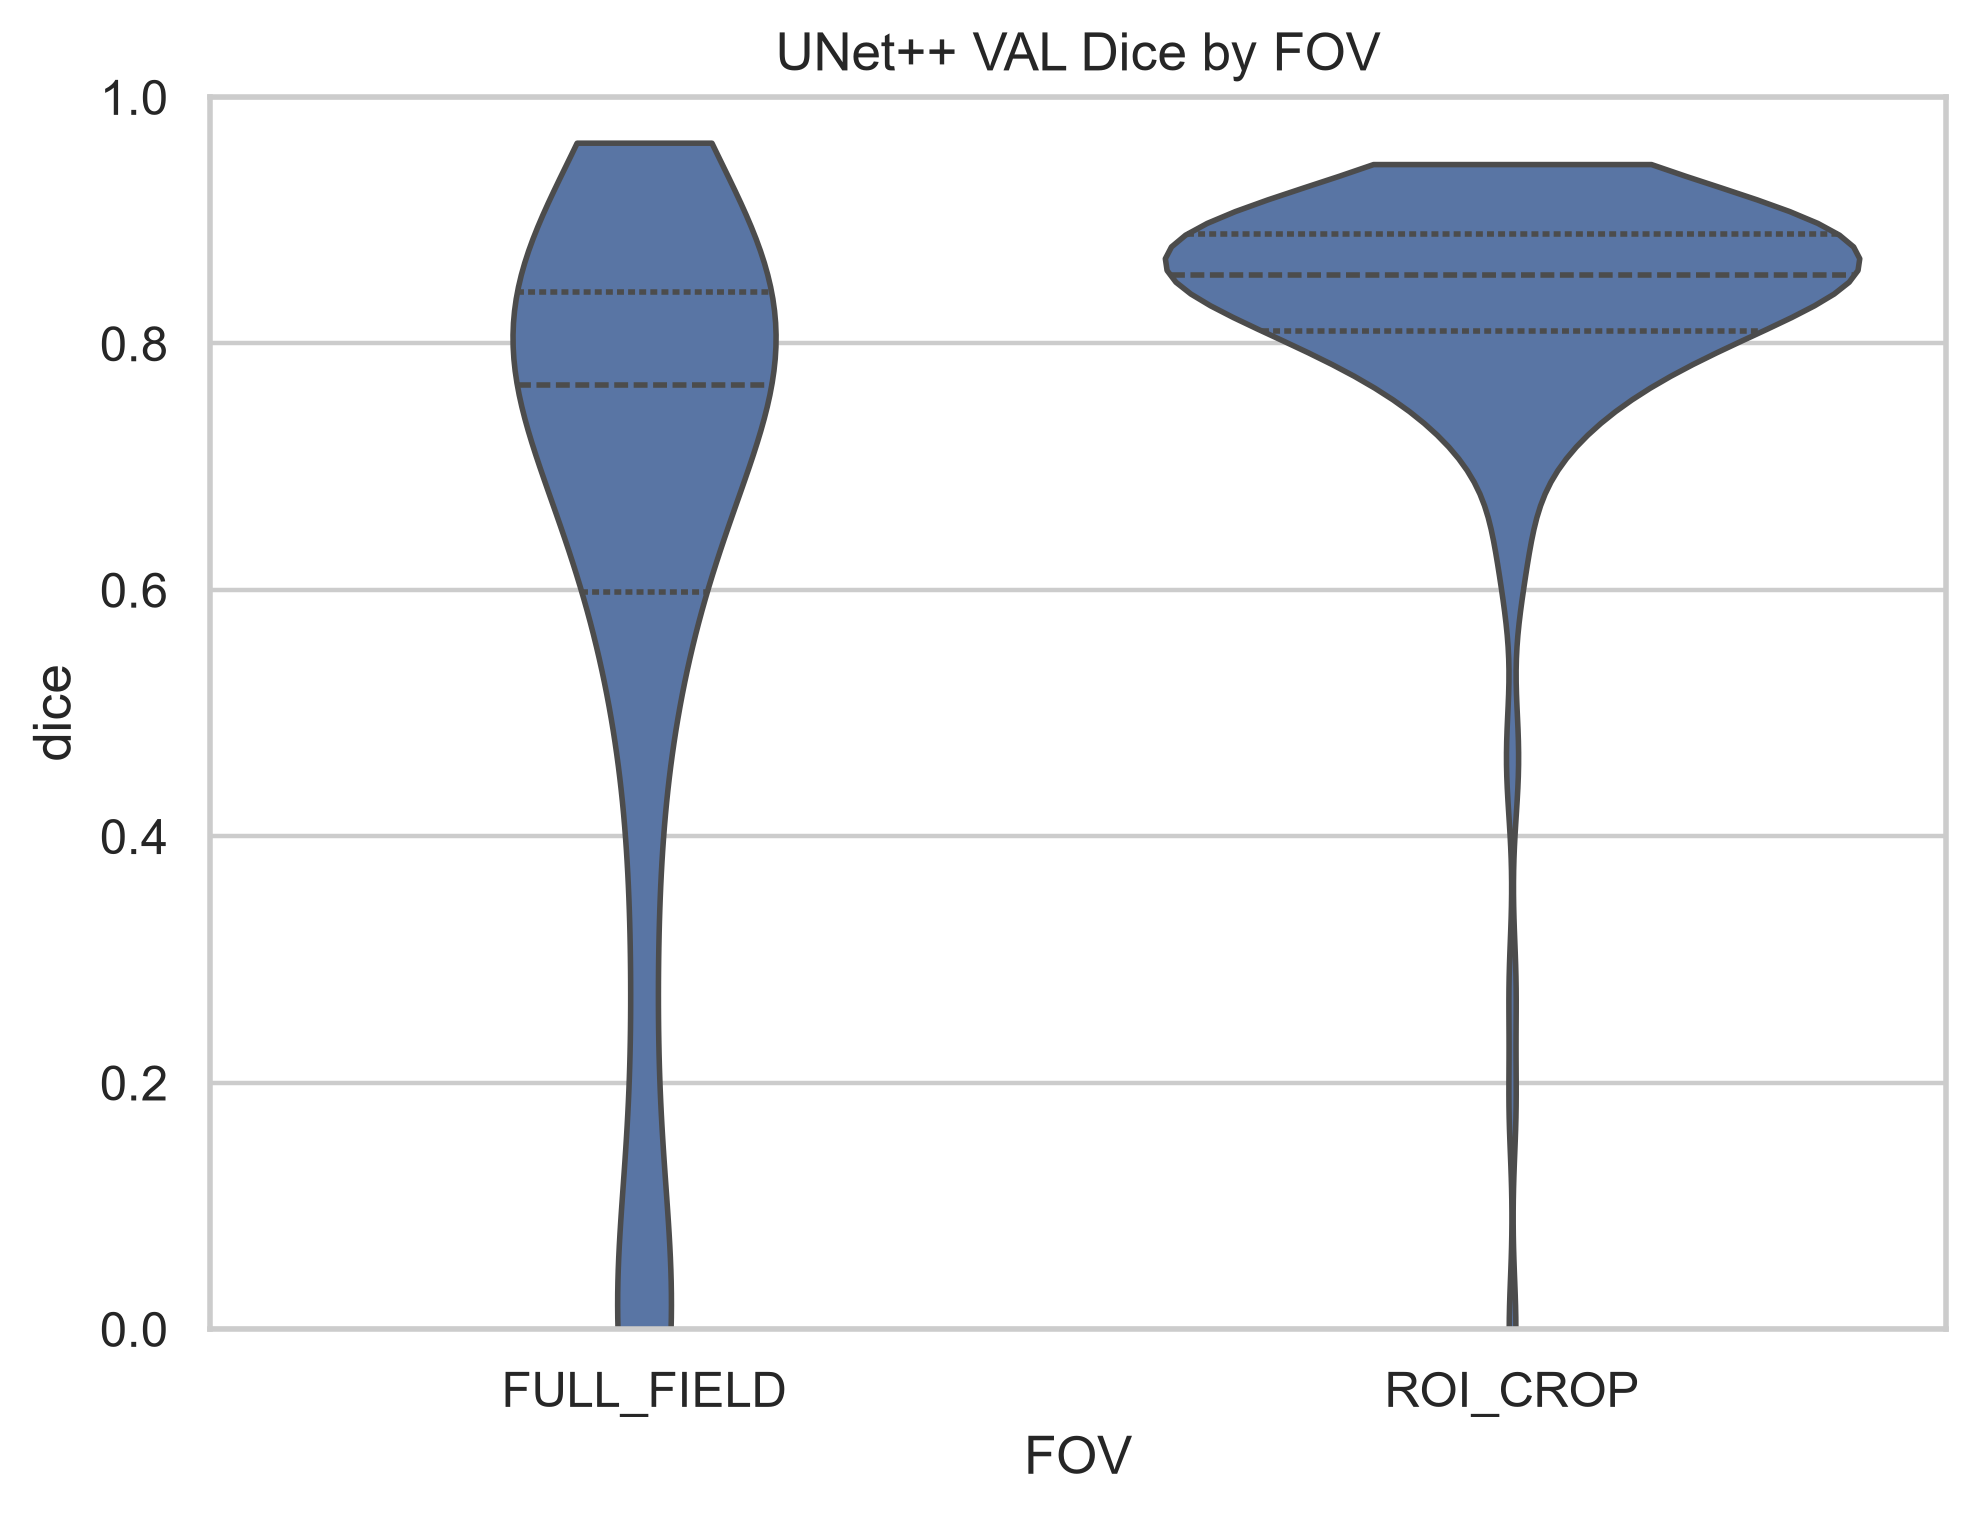

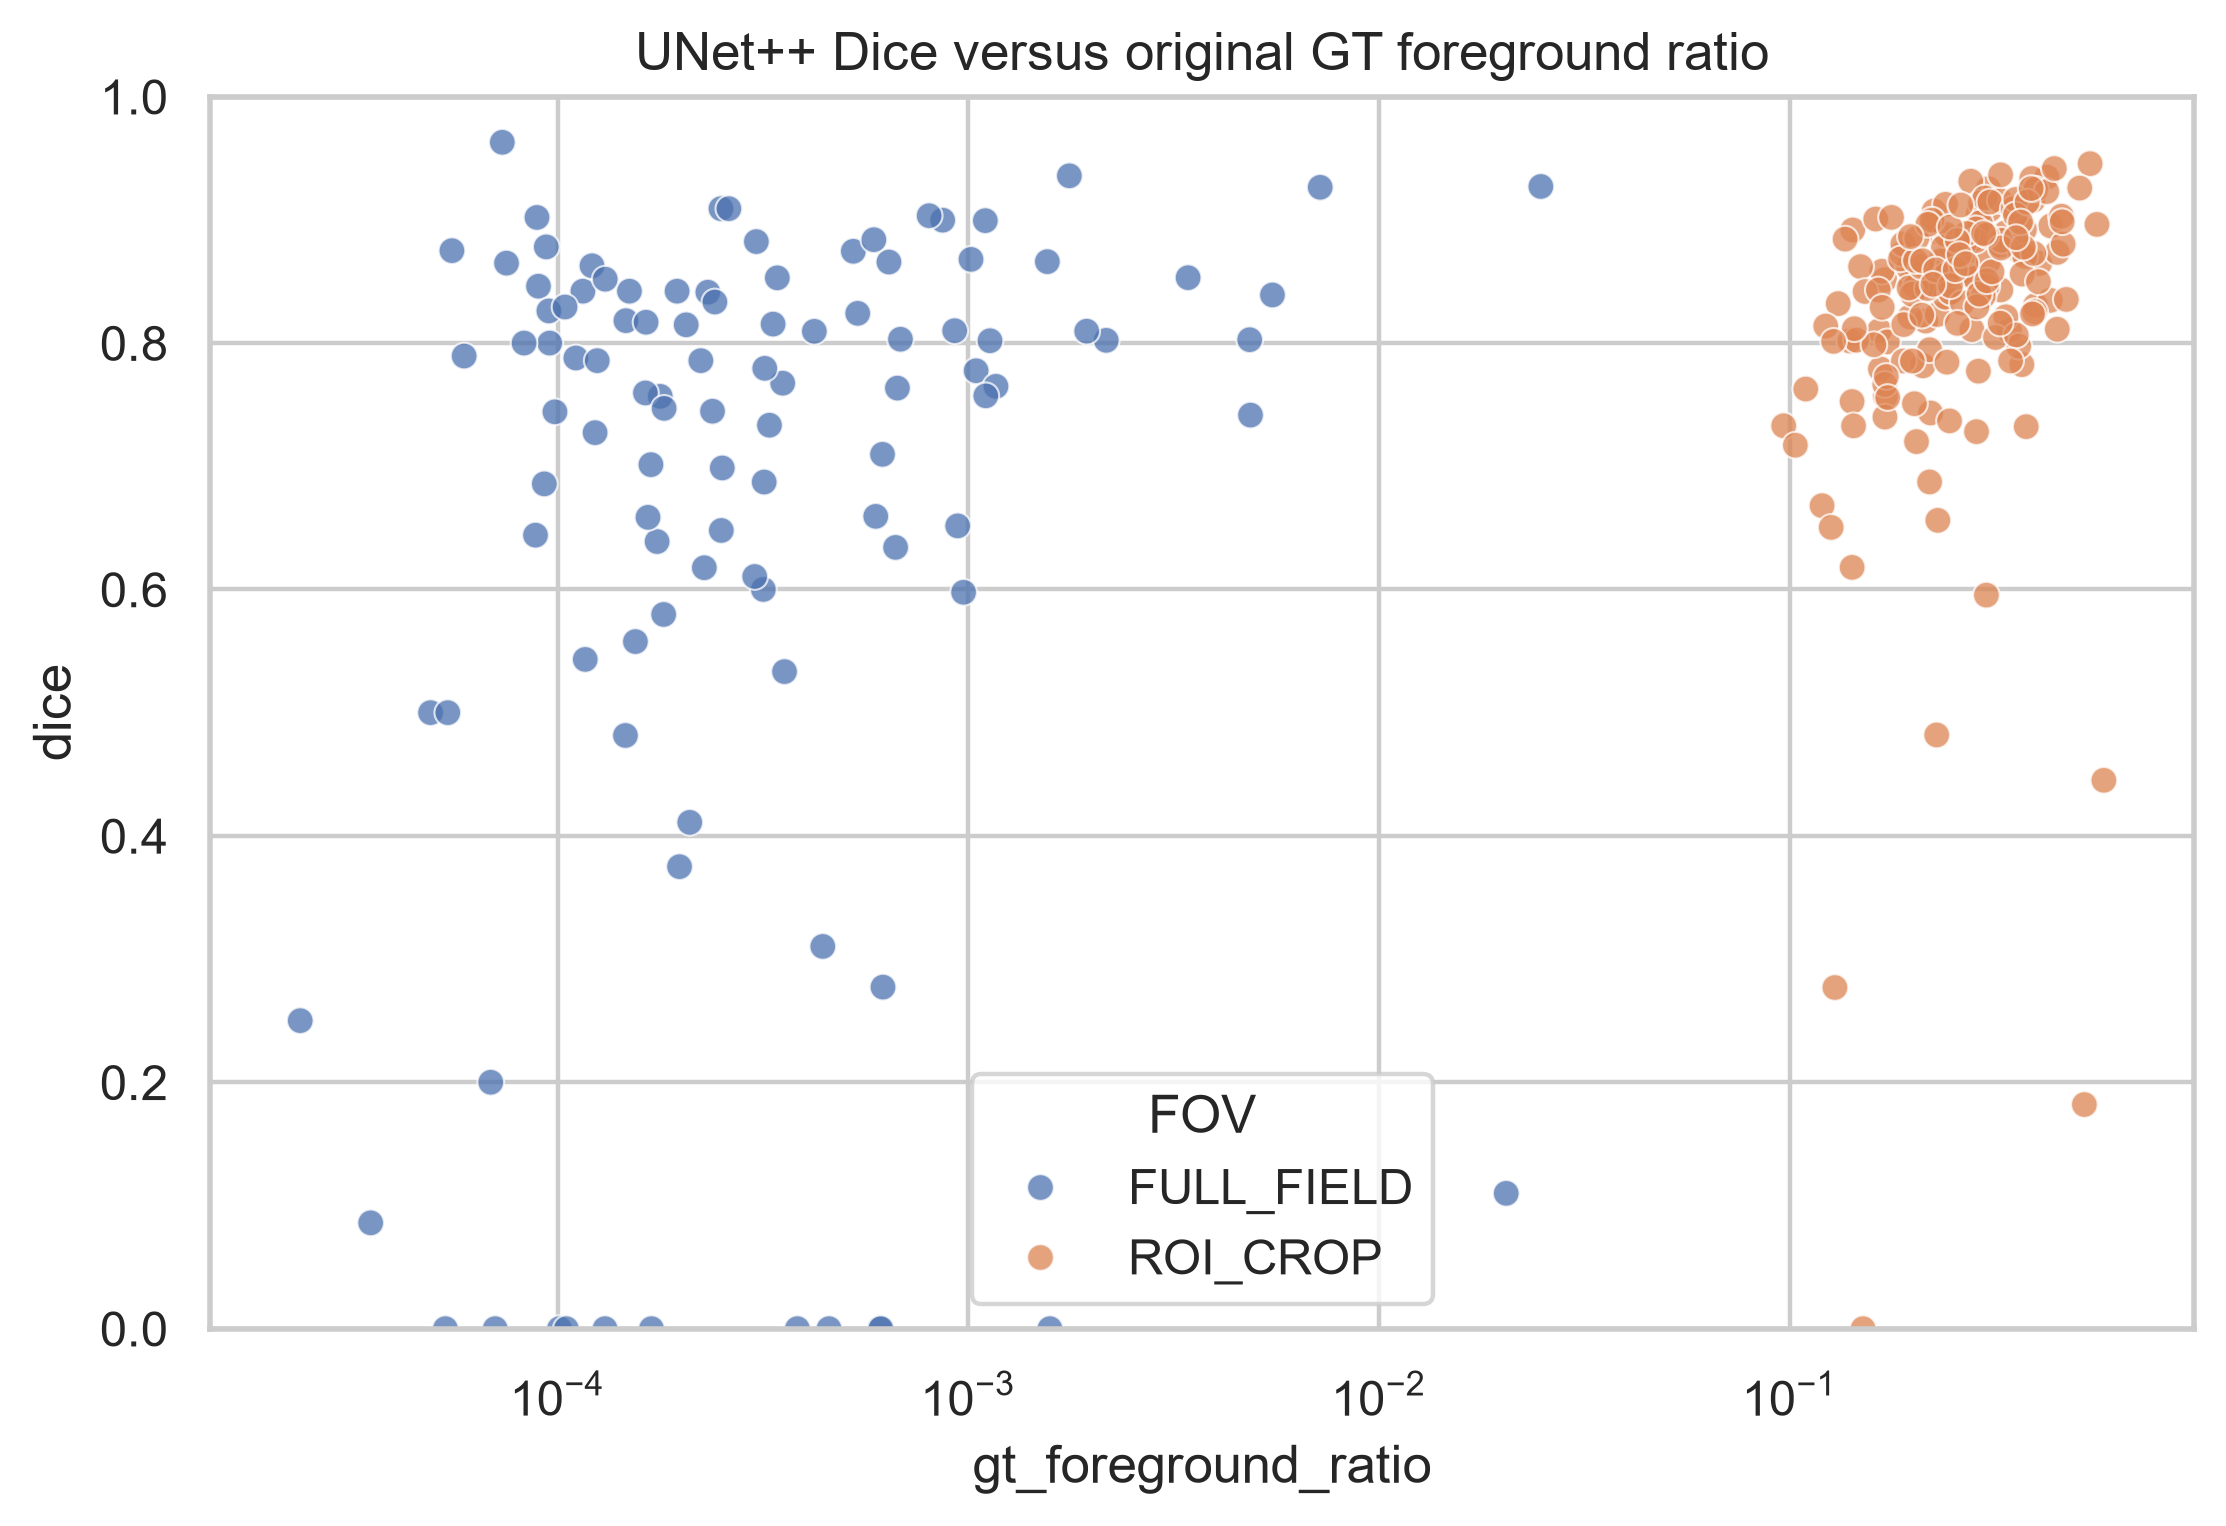

In [4]:
display(x.groupby('FOV').agg(N=('sample_id','size'),Macro_Dice=('dice','mean'),Macro_IoU=('iou','mean'),Precision=('precision','mean'),Recall=('recall','mean')))
display(Image(filename=str(F/'phase11_dice_by_fov_distribution.png'),width=800))
display(Image(filename=str(F/'phase11_dice_vs_foreground_ratio.png'),width=850))

## Category and original-space size failures

,N,Dice,IoU,Precision,Recall
category,,,,,
Bladder_Stone,145,0.744176,0.630995,0.811877,0.771503
Kidney_Stone,114,0.777686,0.670514,0.838606,0.768874
Ureteric_Stone,24,0.801009,0.685006,0.813695,0.832285


,kub_size_v1,GT,Detected,Missed,Recall
0,LARGE,18,17,1,0.944444
1,MEDIUM,36,32,4,0.888889
2,SMALL,29,25,4,0.862069
3,TINY,73,57,16,0.780822


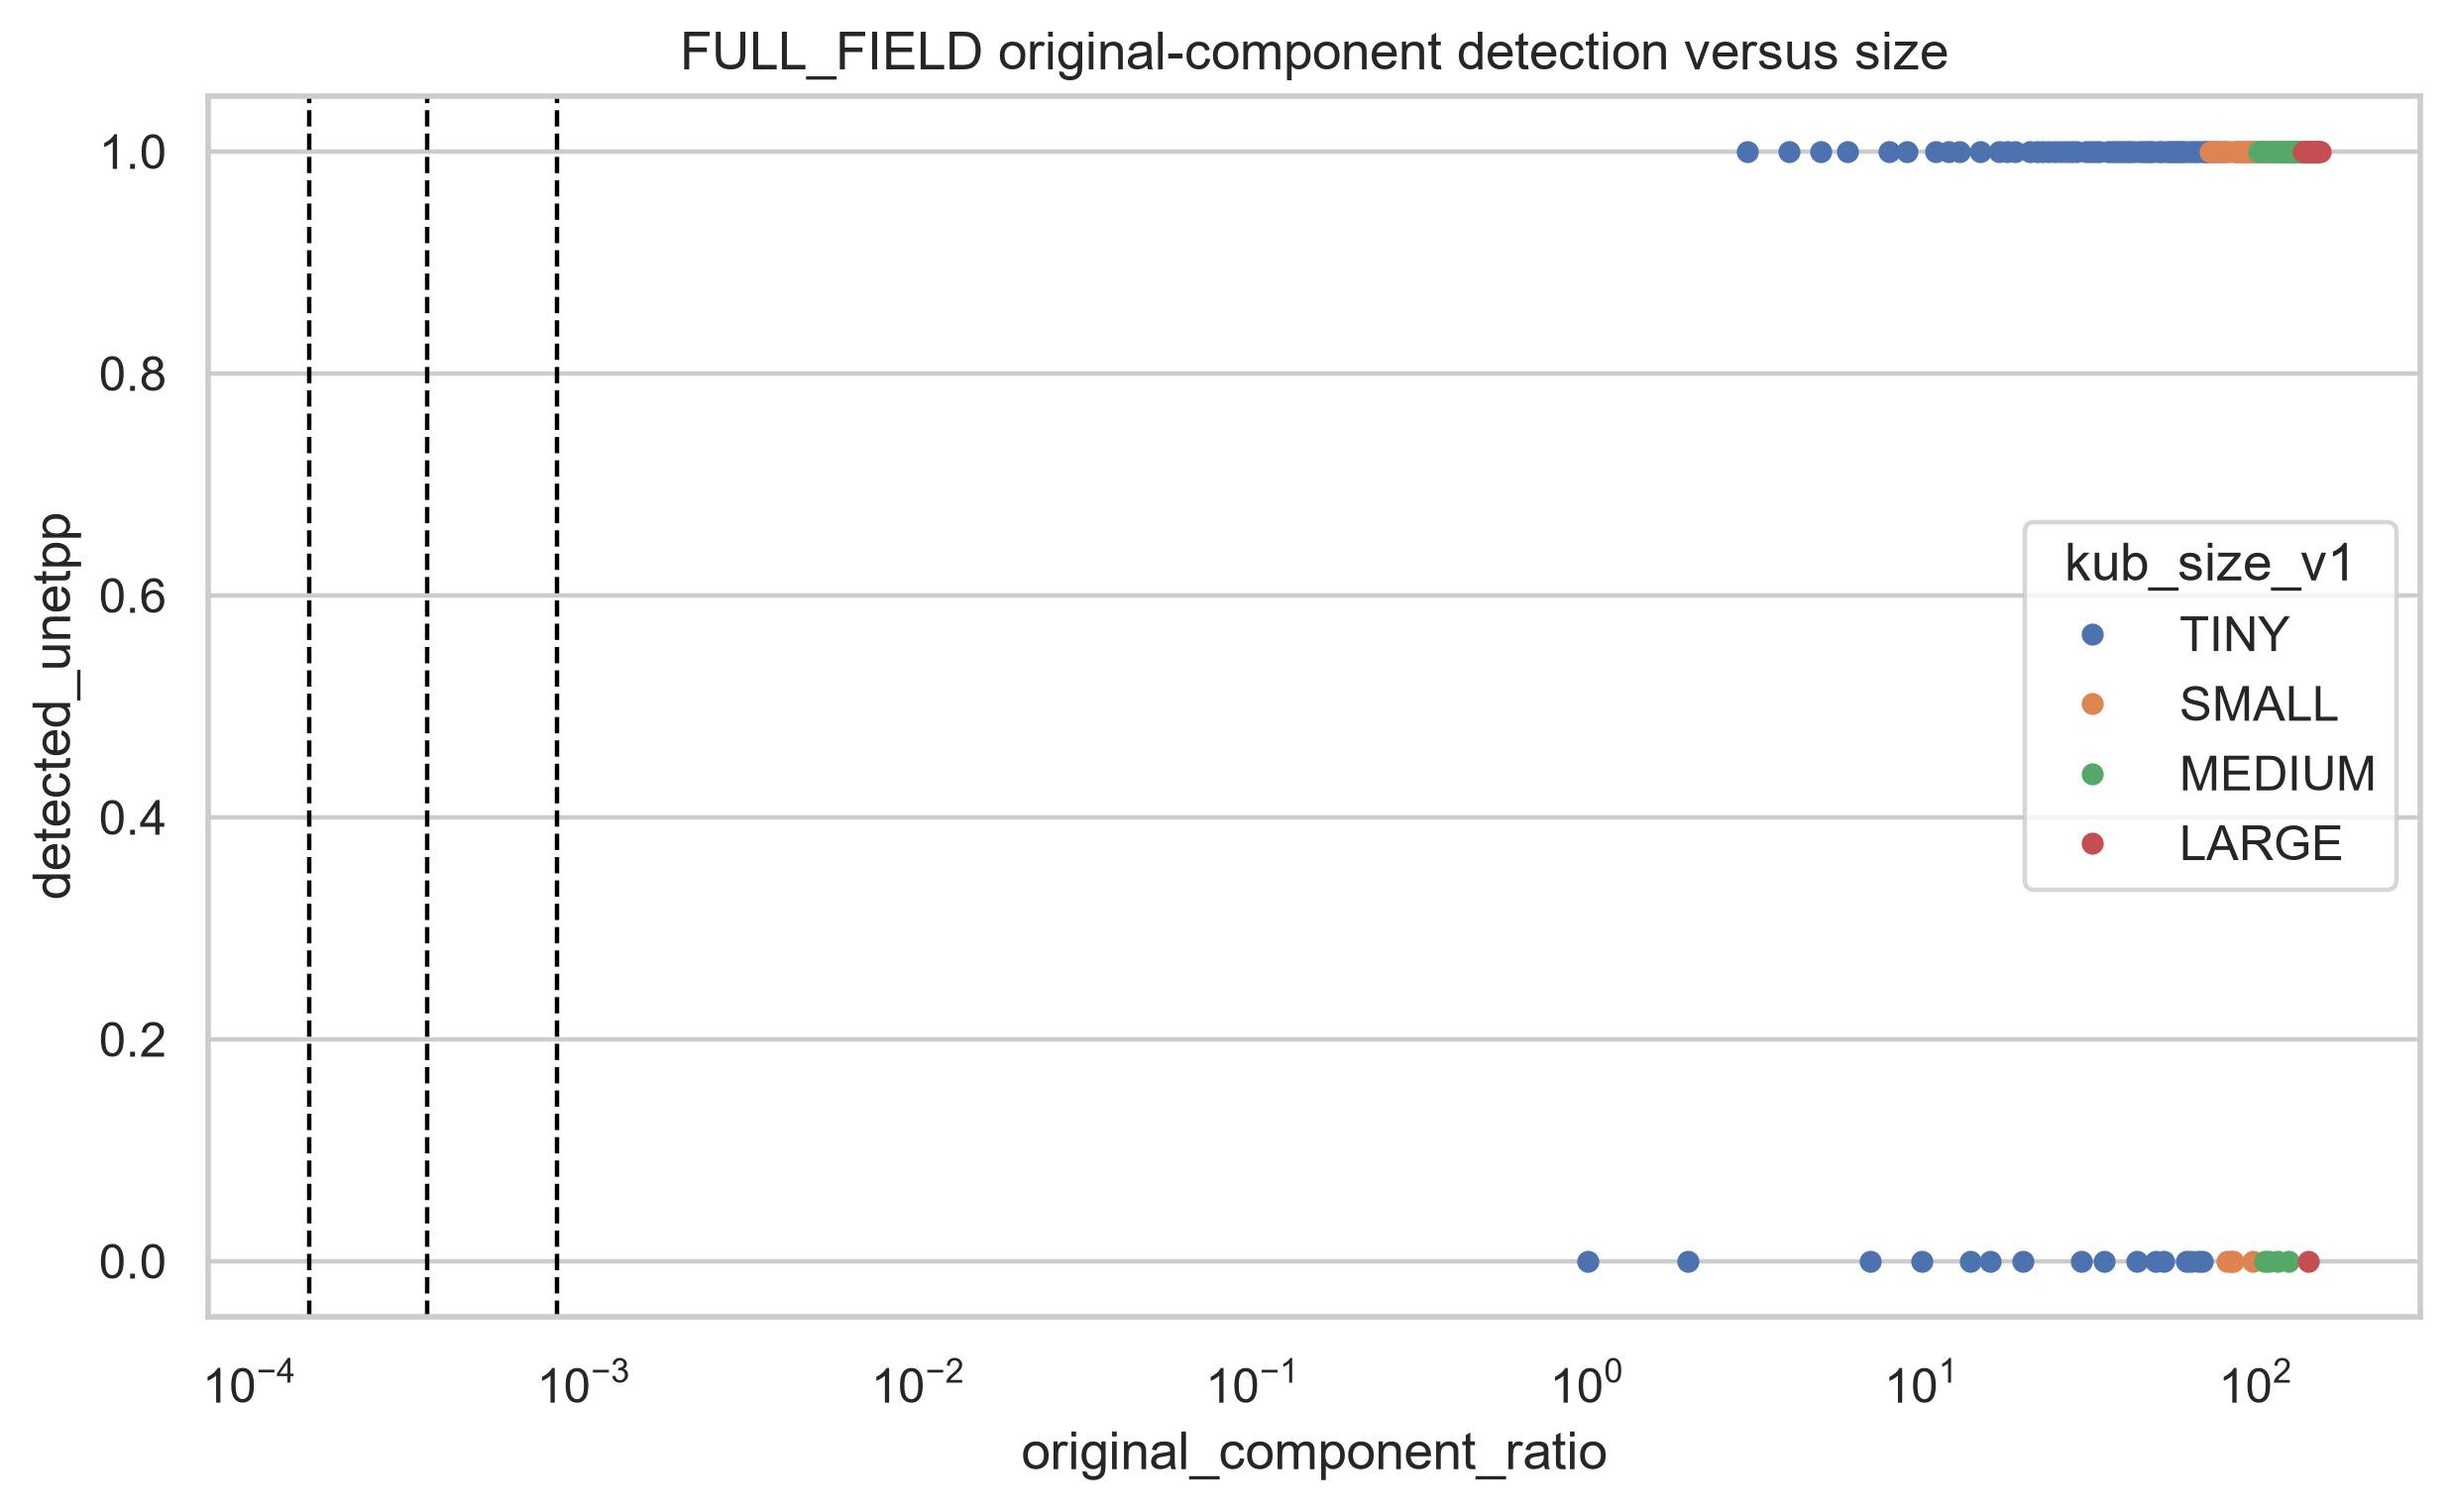

In [5]:
display(x.groupby('category').agg(N=('sample_id','size'),Dice=('dice','mean'),IoU=('iou','mean'),Precision=('precision','mean'),Recall=('recall','mean')))
display(pd.read_csv(T/'phase11_kub_size_failure_summary.csv'))
display(Image(filename=str(F/'phase11_component_detection_vs_size.png'),width=900))

## Multi-component failures and empty predictions

,sample_id,patient_id,category,original_component_count,dice,detected_original,original_components_table,missed_original_components,fraction_detected,detection_class
0,32c06da36a7221dc5369e3ee4723c10c,patient-00041,Bladder_Stone,2,8.412699e-01,2,2,0,1.0,COMPLETE_DETECTION
1,f1afd69d82aff6da8bc39cdcd5f90bf6,patient-00044,Bladder_Stone,2,6.871795e-01,2,2,0,1.0,COMPLETE_DETECTION
2,1fd51712e6a34234a5496ed5d4c26bd0,patient-00046,Bladder_Stone,2,8.333333e-01,2,2,0,1.0,COMPLETE_DETECTION
3,8959dfc29ab5e06d0b2a0f41a4729dde,patient-00048,Bladder_Stone,2,4.814815e-01,1,2,1,0.5,PARTIAL_DETECTION
4,2286db1a7e6b8867cde46a4294ba0c10,patient-00051,Bladder_Stone,2,6.388889e-01,2,2,0,1.0,COMPLETE_DETECTION
5,cf42f77785321f69cbf04efeede747dc,patient-00060,Bladder_Stone,2,6.440678e-01,2,2,0,1.0,COMPLETE_DETECTION
6,a20fe2c1ca04026ab0d036e8dcdd9cca,patient-00062,Bladder_Stone,2,5.797101e-01,1,2,1,0.5,PARTIAL_DETECTION
7,8f5ed38f0453ee55d9813e6dab414707,patient-00077,Bladder_Stone,2,6.585366e-01,2,2,0,1.0,COMPLETE_DETECTION
8,cdc20108edd14a14253e4c488e4fb6ac,patient-00092,Bladder_Stone,2,6.000000e-01,2,2,0,1.0,COMPLETE_DETECTION
9,e6db42e46d012311069580771d4bec32,patient-00094,Bladder_Stone,2,9.090909e-01,2,2,0,1.0,COMPLETE_DETECTION


,sample_id,patient_id,category,FOV,component_count_original,dominant_object_stratum,gt_foreground_ratio,dice,hd95_valid
16,b0473630de9211114c94c7dc0363ebd9,patient-00053,Bladder_Stone,FULL_FIELD,1,TINY,0.000101,4.166667e-09,False
24,8c8d2107815002b7913bd6a42f93b394,patient-00107,Bladder_Stone,FULL_FIELD,2,TINY,0.000071,9.090909e-09,False
26,ad4af1ce1b3dde6ad04fa095aacd92f5,patient-00113,Bladder_Stone,FULL_FIELD,1,TINY,0.000053,8.333333e-09,False
27,abe658fa57a12b1665a96d00beeffae0,patient-00115,Bladder_Stone,FULL_FIELD,2,MEDIUM,0.000609,1.265823e-09,False
48,f860cbfe7c79e5772795a64bac5de7e7,patient-01207,Bladder_Stone,FULL_FIELD,1,TINY,0.000105,4.347826e-09,False
54,e1e165d69d6844c8a599786d865cdd21,patient-01714,Bladder_Stone,FULL_FIELD,2,TINY,0.000169,2.272727e-09,False
132,14d07b995aba3f2559d9a474c586495c,patient-00578,Bladder_Stone,ROI_CROP,1,ROI_NOT_PRIMARY_BINNED,0.150943,2.758925e-12,False
184,5dd4436a2065b8855ce1dfbed228bce7,patient-00570,Kidney_Stone,FULL_FIELD,2,SMALL,0.000384,1.234568e-09,False


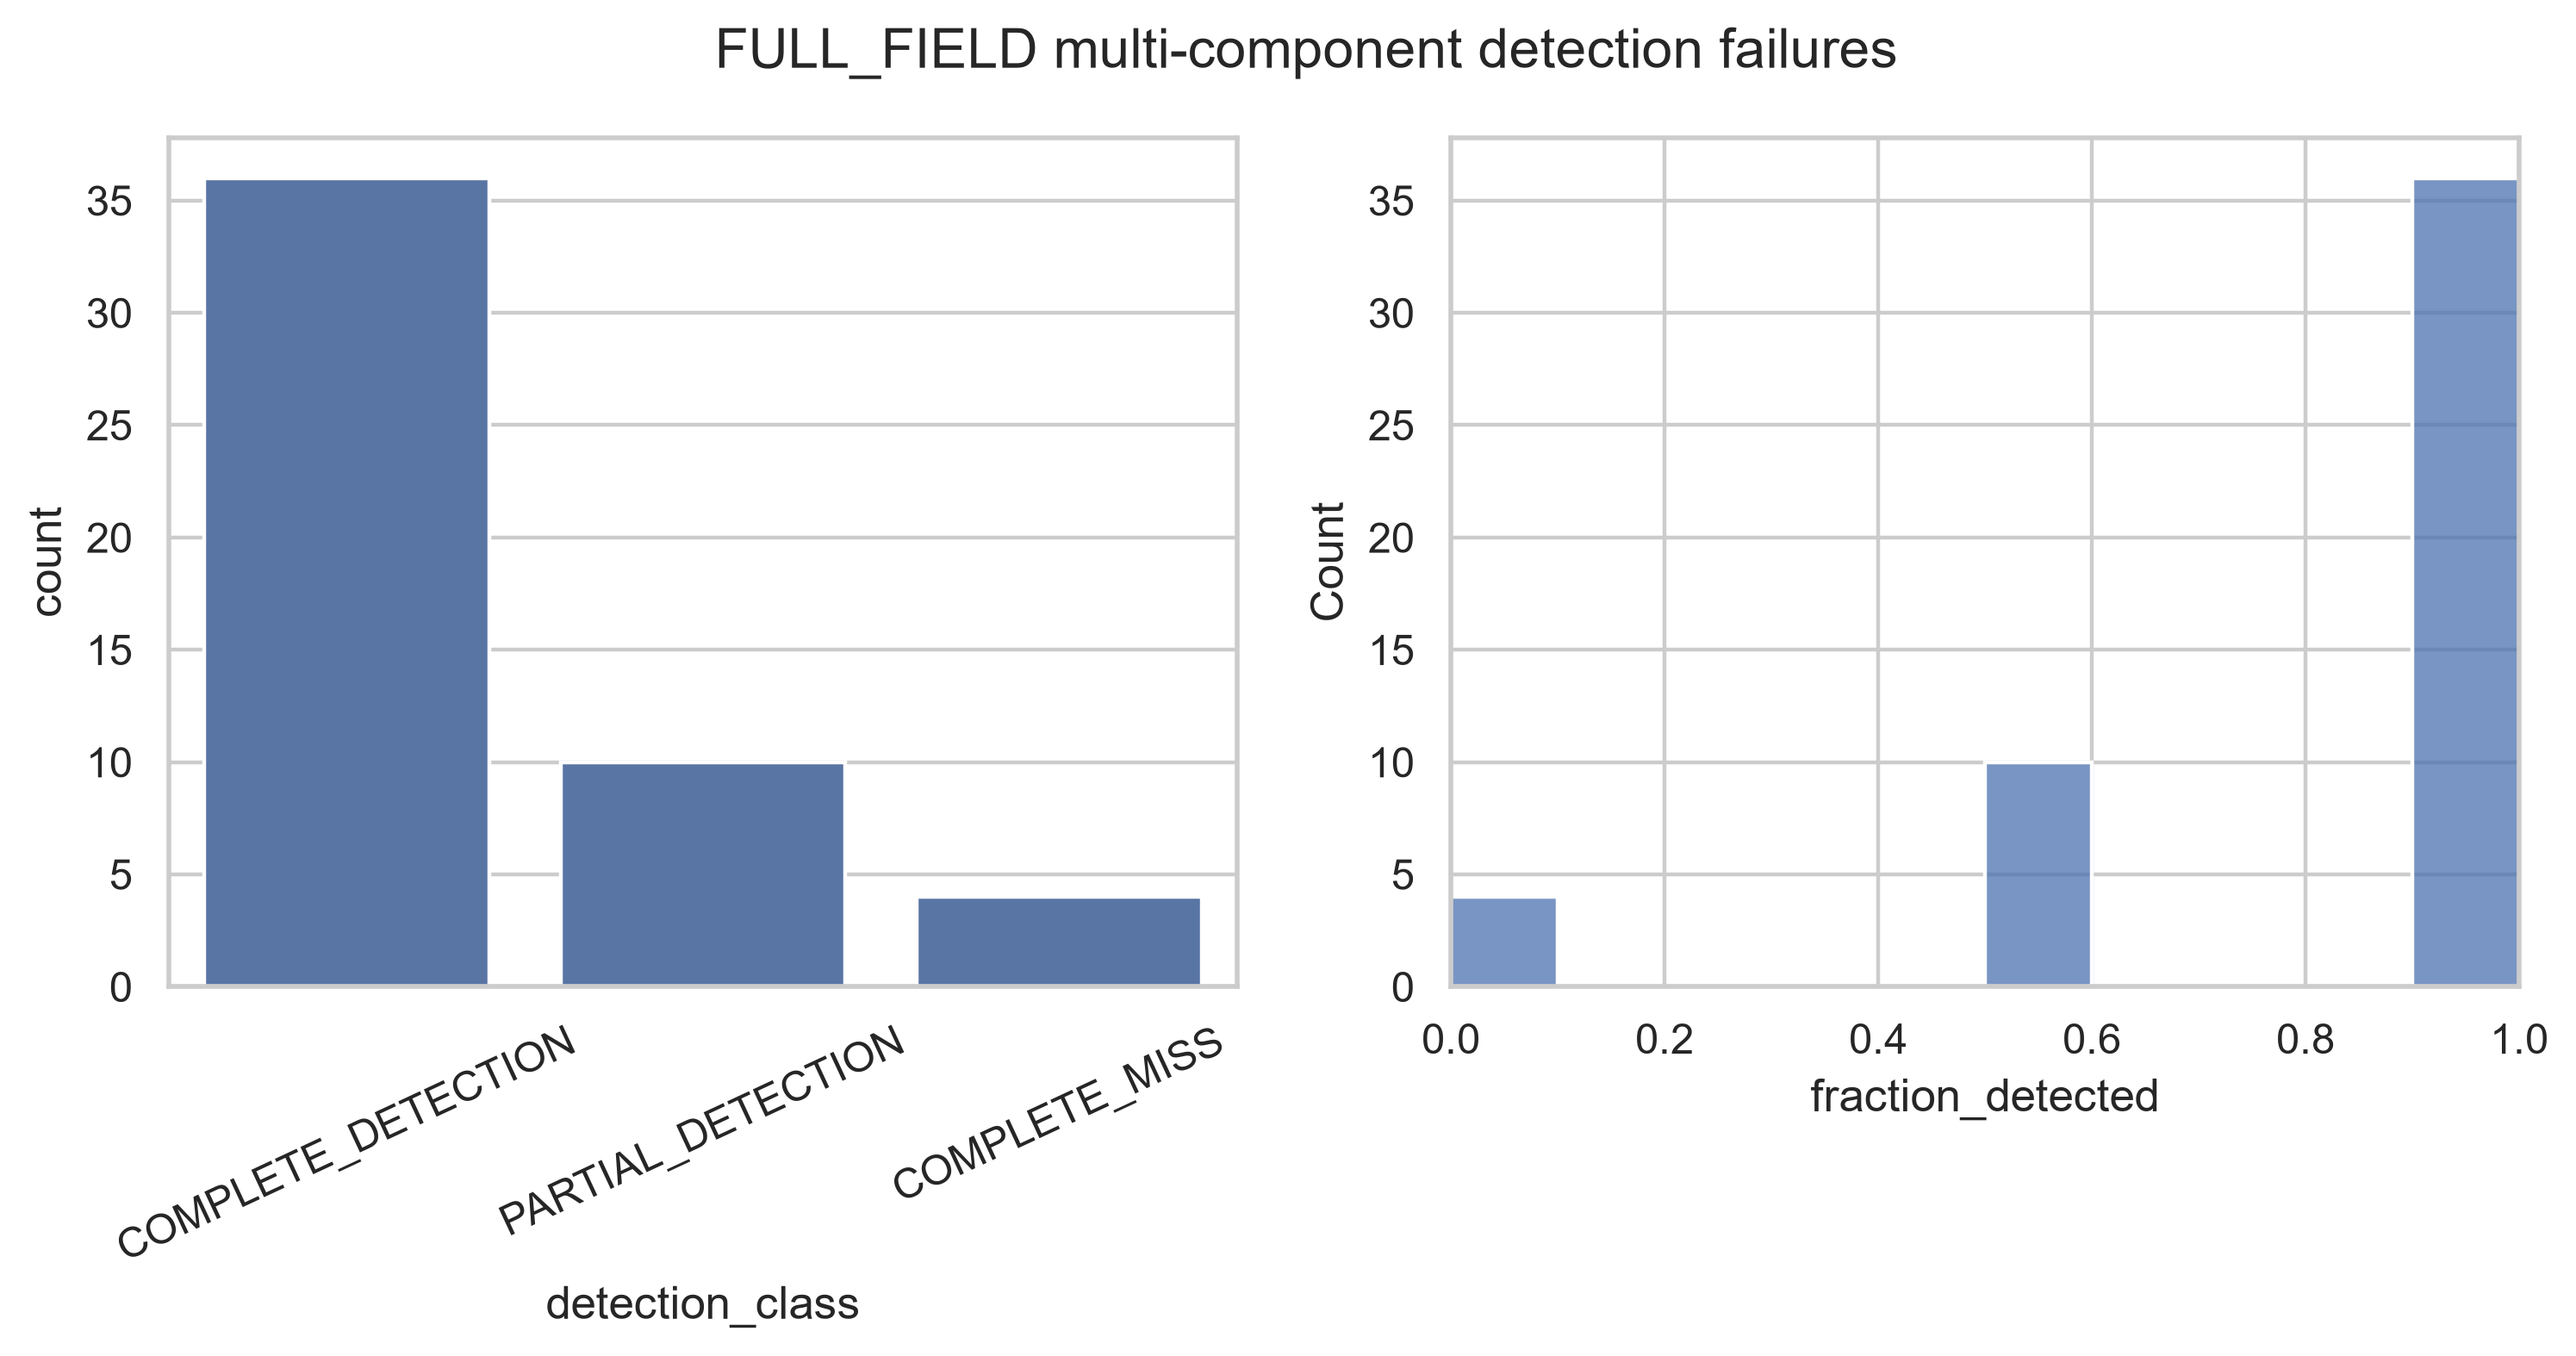

In [6]:
display(pd.read_csv(T/'phase11_kub_multicomponent_failure.csv'))
display(x[x.empty_prediction][['sample_id','patient_id','category','FOV','component_count_original','dominant_object_stratum','gt_foreground_ratio','dice','hd95_valid']])
display(Image(filename=str(F/'phase11_multicomponent_failure.png'),width=950))

## HD95 and precision–recall failure modes

,FOV,hd95_valid,N
0,FULL_FIELD,False,7
1,FULL_FIELD,True,99
2,ROI_CROP,False,1
3,ROI_CROP,True,176


{'low_dice_decile': {'cutoff': 0.5461063385009766, 'comparison': 'dice <= cutoff', 'n': 29}, 'high_hd95_decile': {'cutoff': 83.07246563841615, 'comparison': 'valid hd95 >= cutoff', 'n': 28}, 'high_fp_decile': {'cutoff': 4.0, 'comparison': 'fp evaluation components >= cutoff', 'n': 39}, 'label': 'descriptive failure-analysis strata; not tuning or deployment thresholds'}


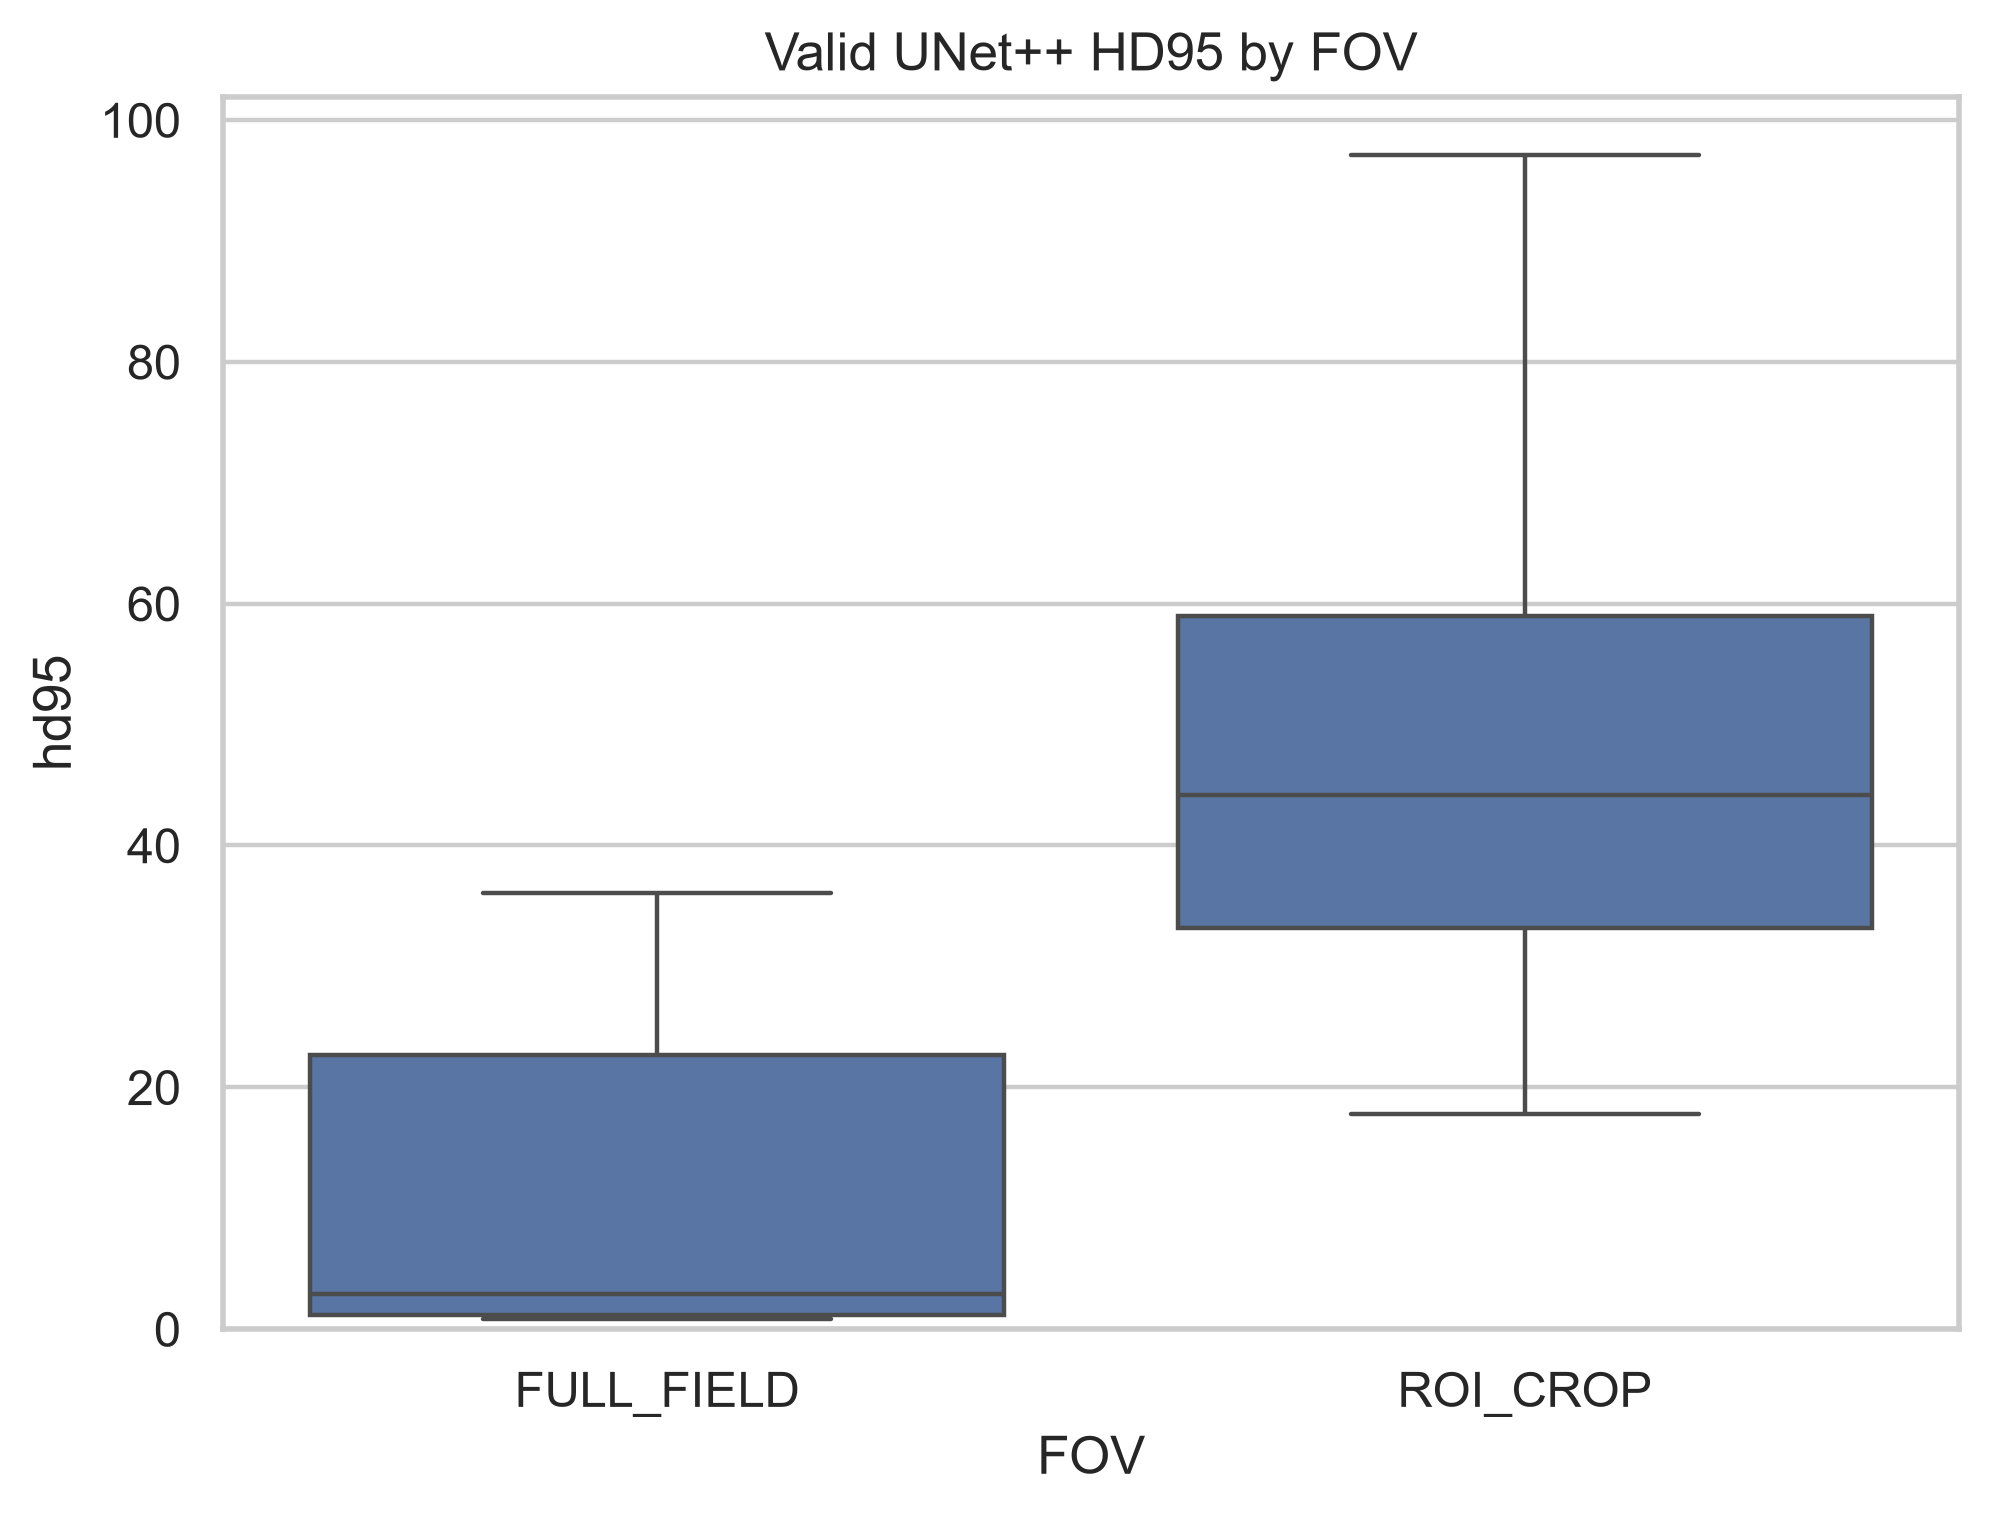

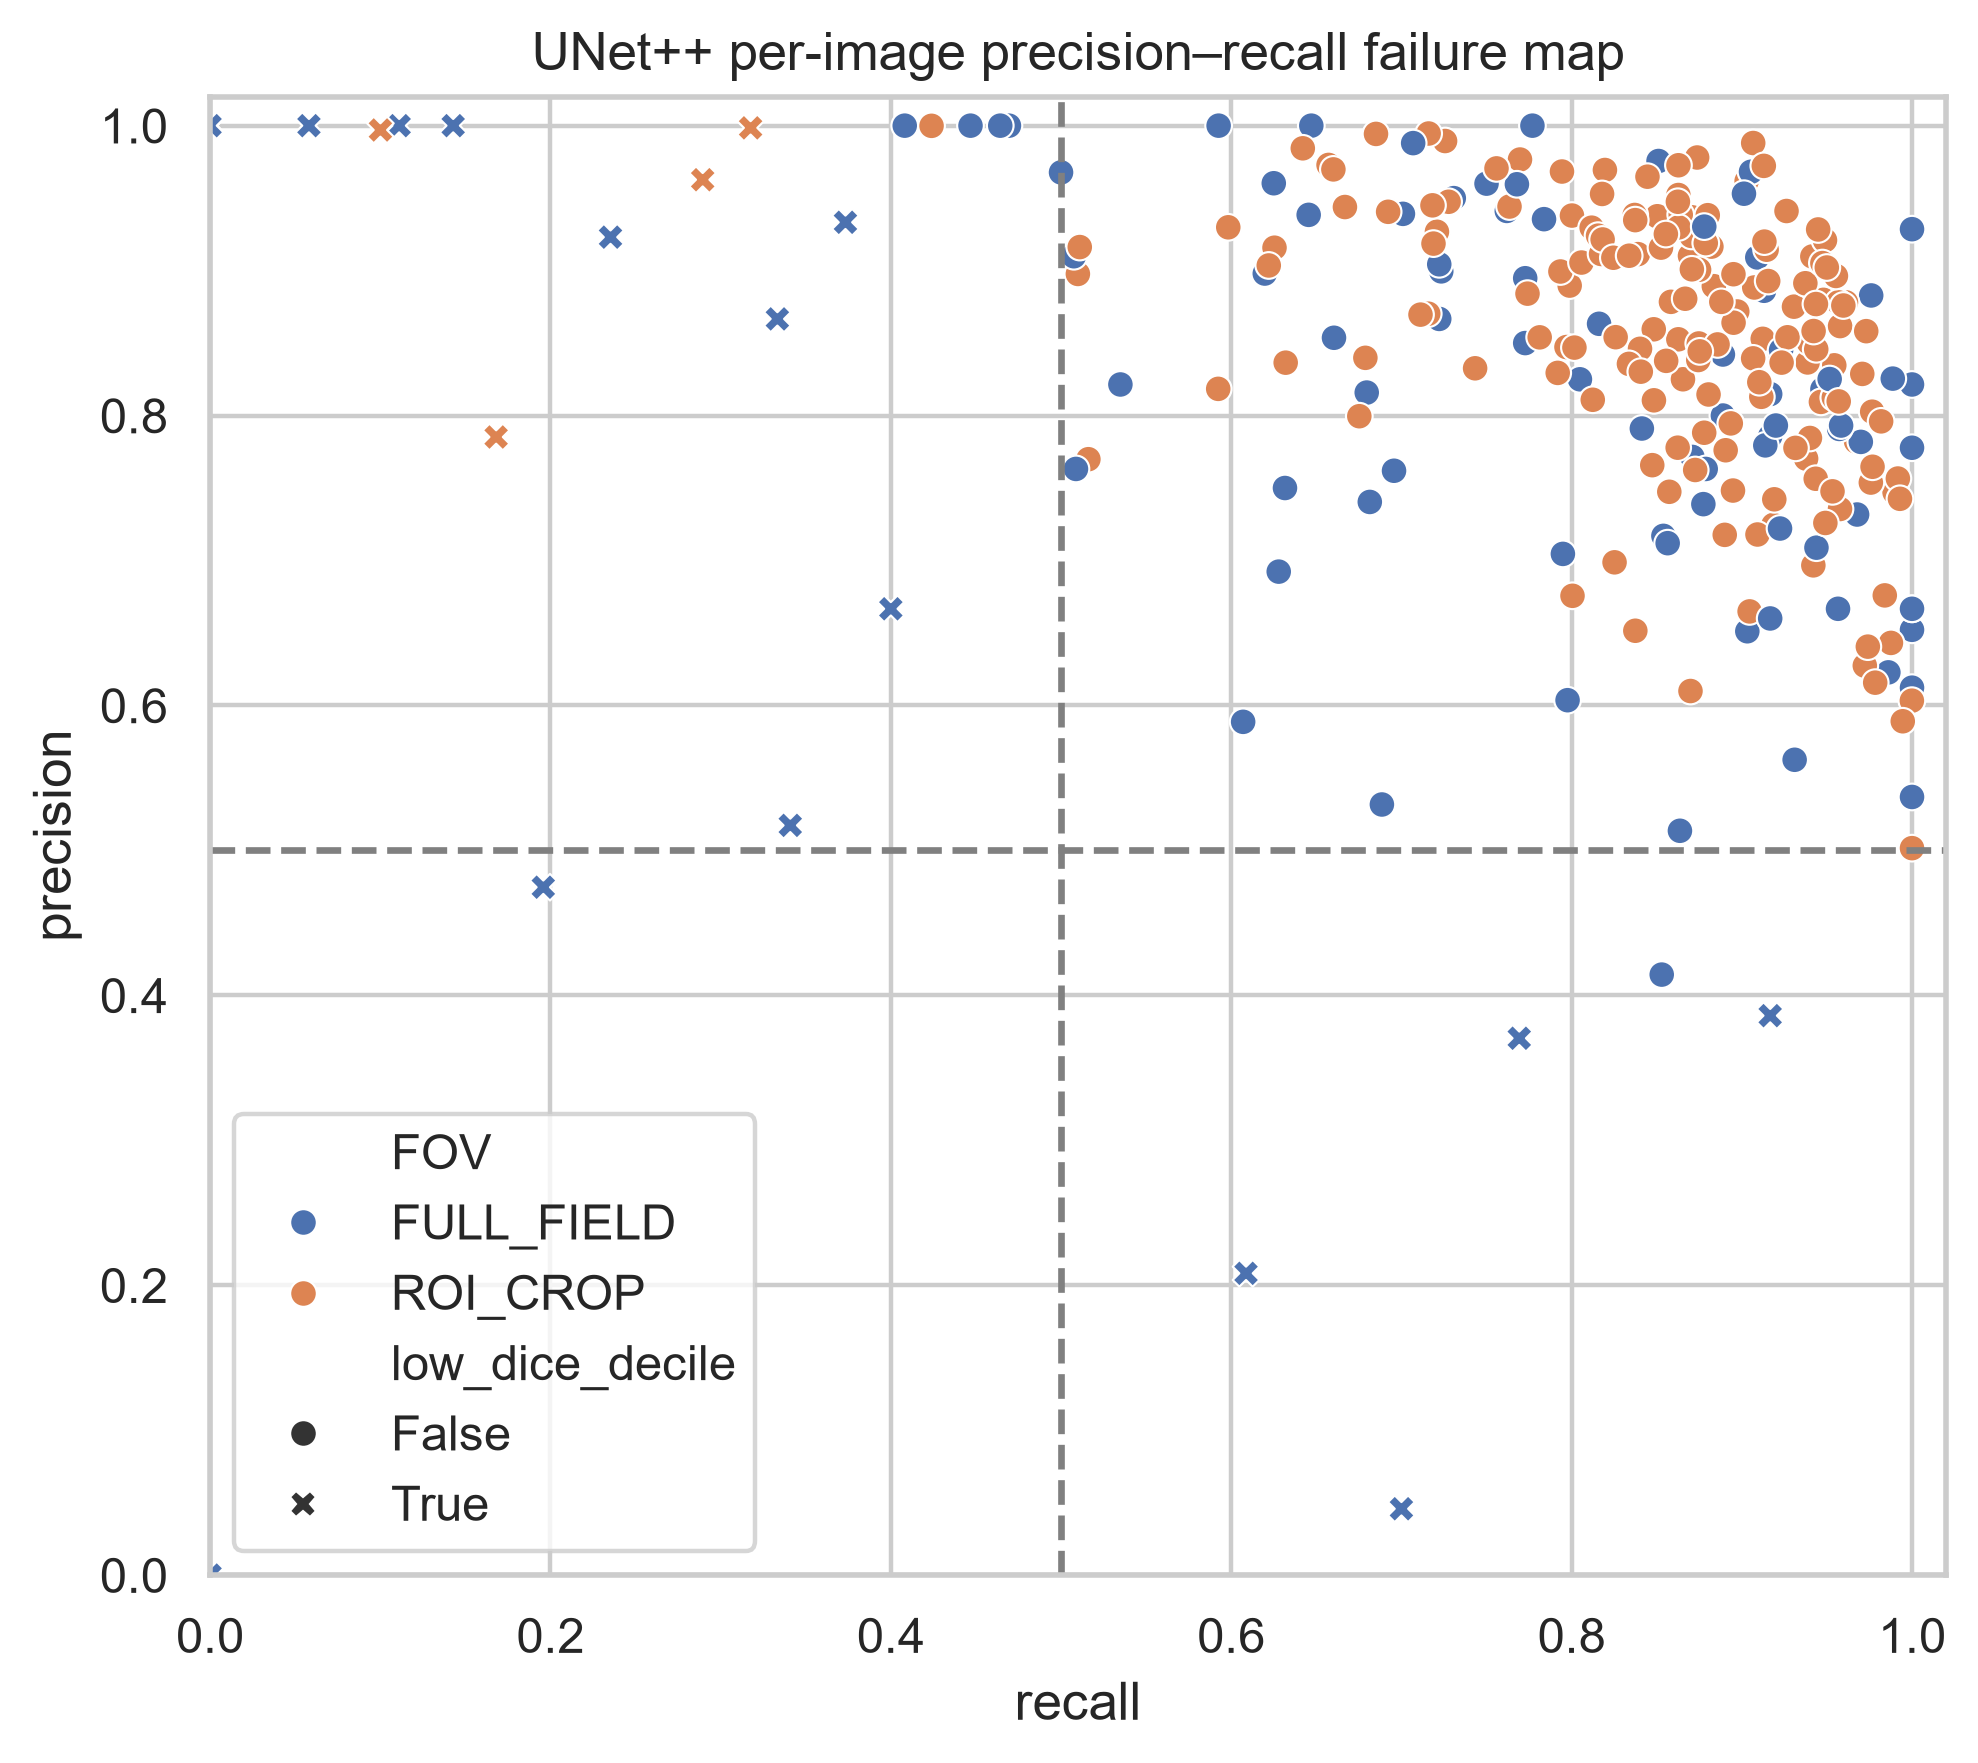

In [7]:
display(x.groupby(['FOV','hd95_valid']).size().rename('N').reset_index())
print(cut)
display(Image(filename=str(F/'phase11_hd95_by_fov.png'),width=800))
display(Image(filename=str(F/'phase11_precision_recall_failure_map.png'),width=800))

## FP burden and DeepLabV3+ comparator

,sample_id,category,FOV,dominant_object_stratum,dice,fp_eval_components,dice_deeplabv3plus,fp_deeplabv3plus
0,66b947d8ead11ae1260bc3142ca1707d,Bladder_Stone,FULL_FIELD,TINY,0.875000,0,0.232143,2
1,608acc38d4a151803e72f2f033ade67e,Bladder_Stone,FULL_FIELD,MEDIUM,0.874494,0,0.836066,0
2,774123a57e11f802de7ed923c13b7120,Bladder_Stone,FULL_FIELD,TINY,0.901961,0,0.754098,0
3,68509b1fa766f0a9bb074a3640f5ea05,Bladder_Stone,FULL_FIELD,TINY,0.846154,0,0.591549,1
4,f5a92a209cd5010d230ecaab8556ef89,Bladder_Stone,FULL_FIELD,TINY,0.842105,1,0.814815,0
...,...,...,...,...,...,...,...,...
278,7af80b139764d918ec3a943e6a3f8b5c,Ureteric_Stone,ROI_CROP,ROI_NOT_PRIMARY_BINNED,0.888917,0,0.913395,0
279,142bca47012895bafb72eaea84a586cb,Ureteric_Stone,ROI_CROP,ROI_NOT_PRIMARY_BINNED,0.816173,1,0.760574,0
280,8bde4e3c4709ce073d0f5075bf5aff17,Ureteric_Stone,ROI_CROP,ROI_NOT_PRIMARY_BINNED,0.750782,2,0.908147,0
281,e2dcb067e48ae5ab3cde4f3eafd2ddf1,Ureteric_Stone,ROI_CROP,ROI_NOT_PRIMARY_BINNED,0.815975,3,0.825049,0


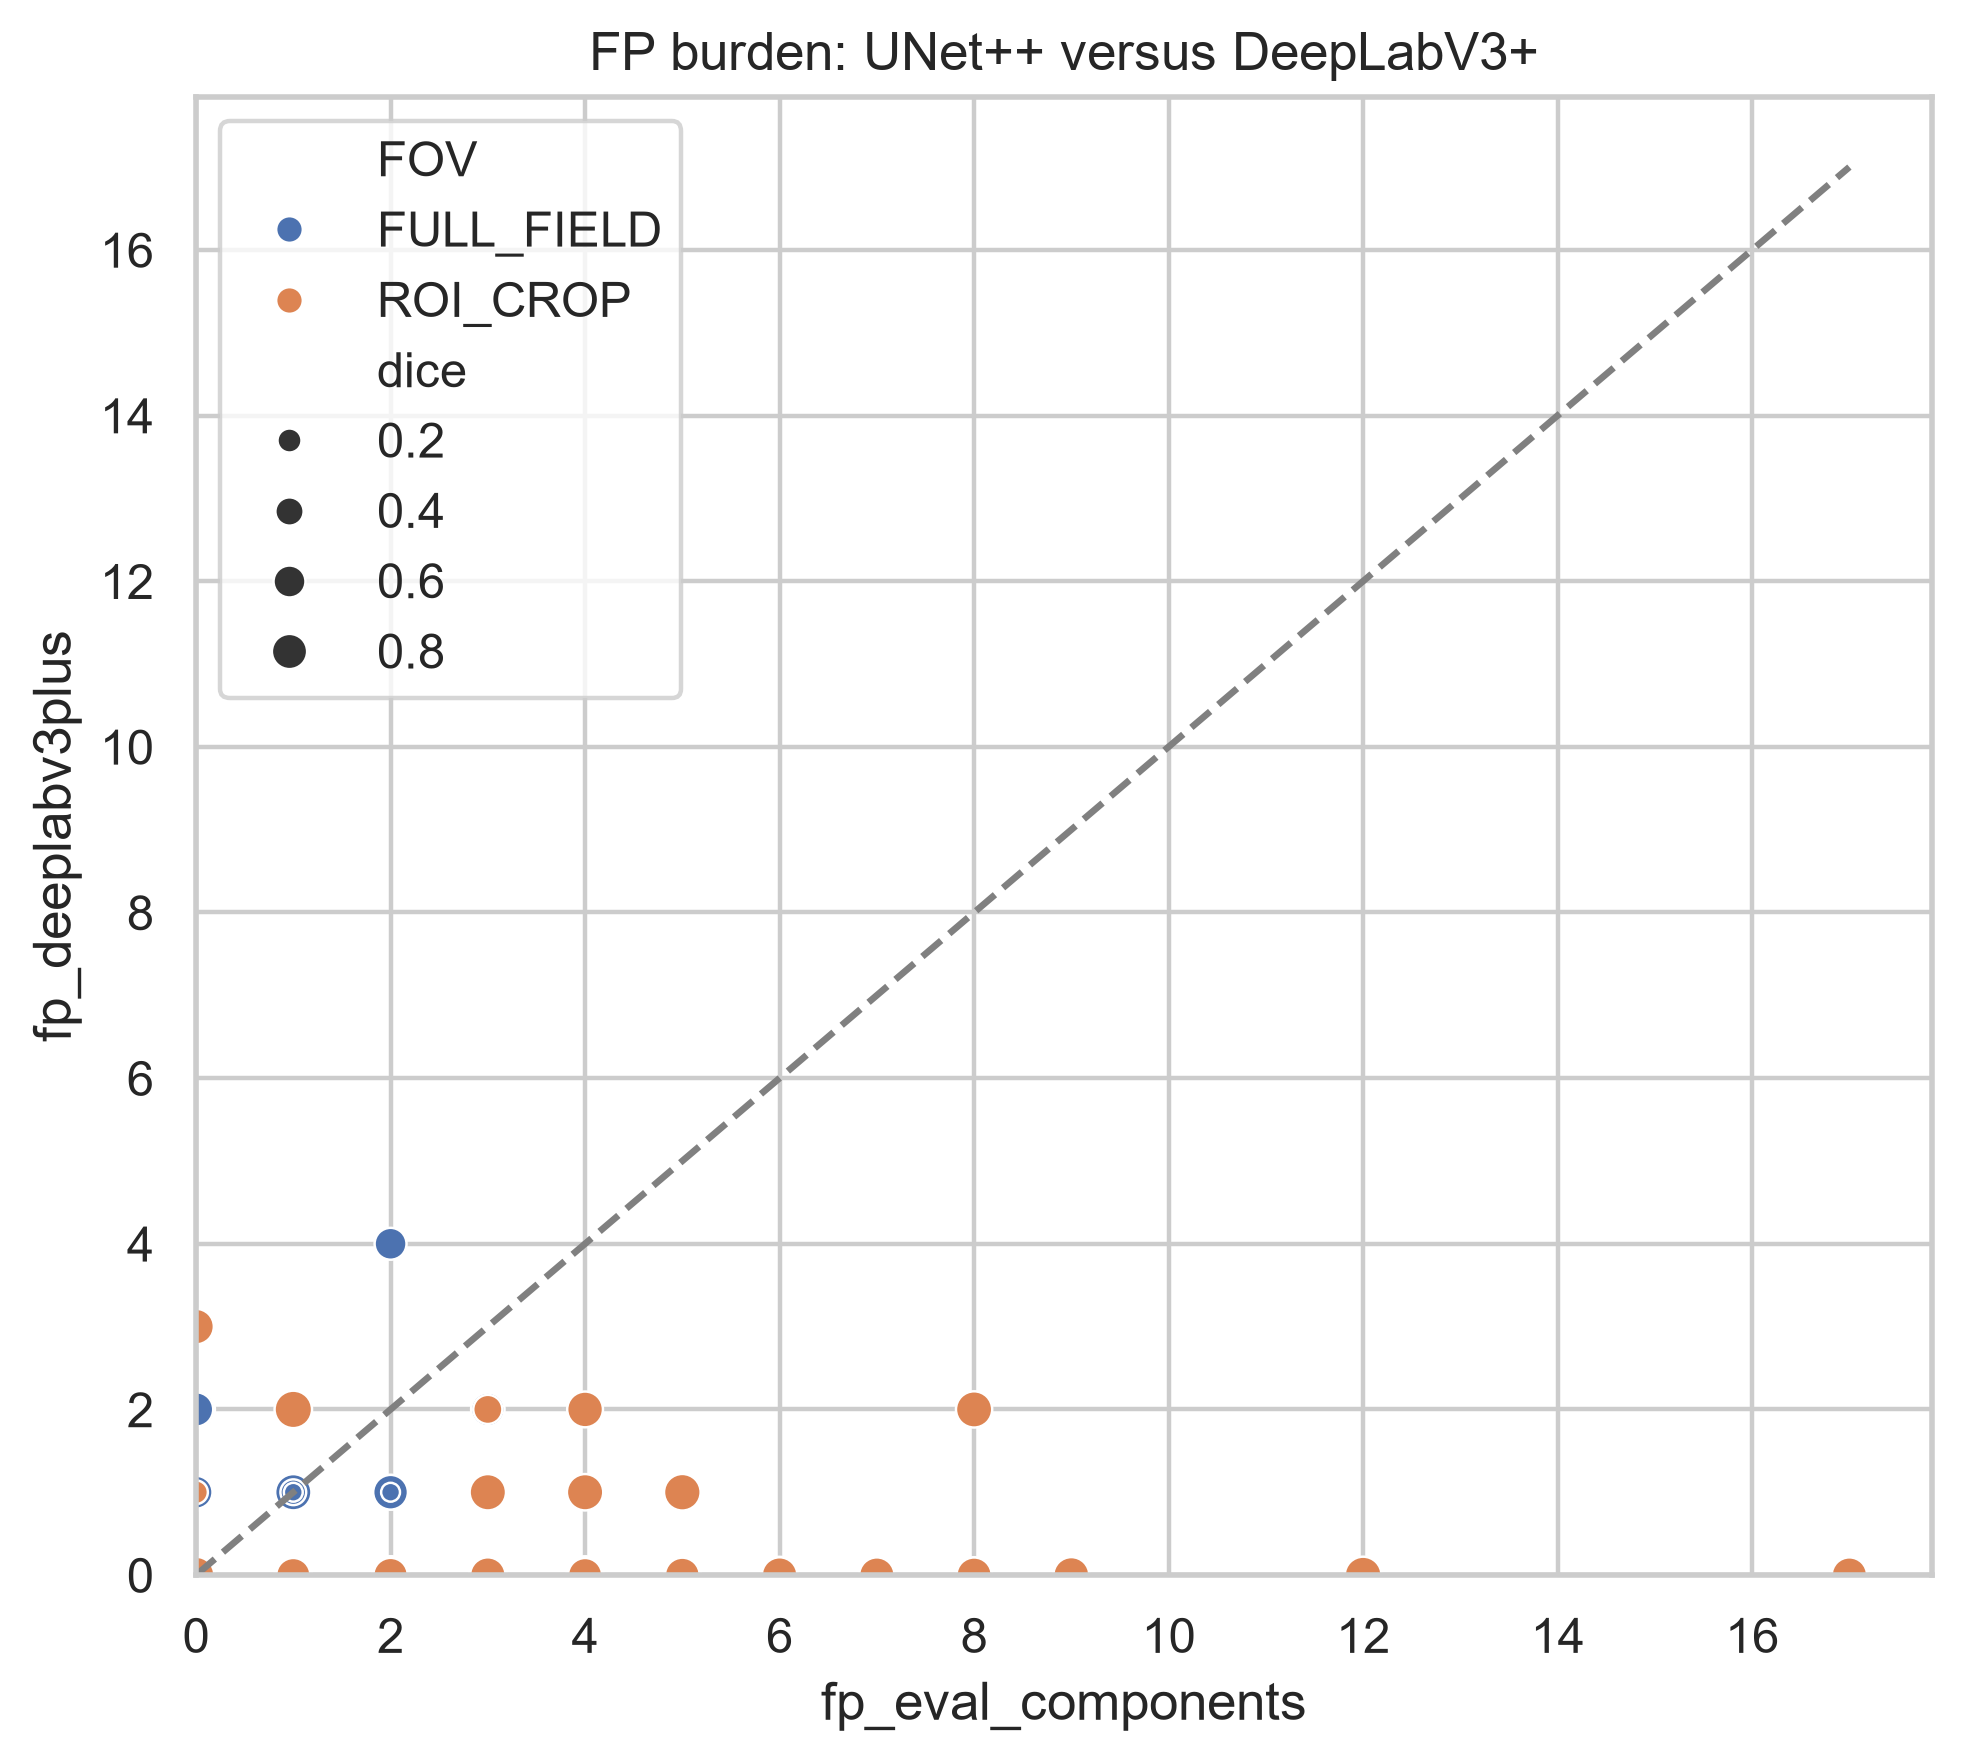

In [8]:
display(pd.read_csv(T/'phase11_fp_unetpp_vs_deeplab.csv'))
display(Image(filename=str(F/'phase11_fp_burden_unetpp_vs_deeplab.png'),width=800))

## Cross-model failure overlap

,Failure_Category,N_Images
0,ALL_FOUR_NOT_LOW,241
1,ARCHITECTURE_DISAGREEMENT,17
2,ALL_FOUR_LOW,16
3,DEEPLAB_UNIQUELY_SUCCESSFUL,4
4,DEEPLAB_UNIQUELY_LOW,2
5,UNETPP_UNIQUELY_LOW,2
6,UNETPP_UNIQUELY_SUCCESSFUL,1
7,COMPONENT_MISSED_BY_ALL,20
8,COMPONENT_DETECTED_BY_ALL,110
9,COMPONENT_DETECTED_UNETPP_ONLY,4


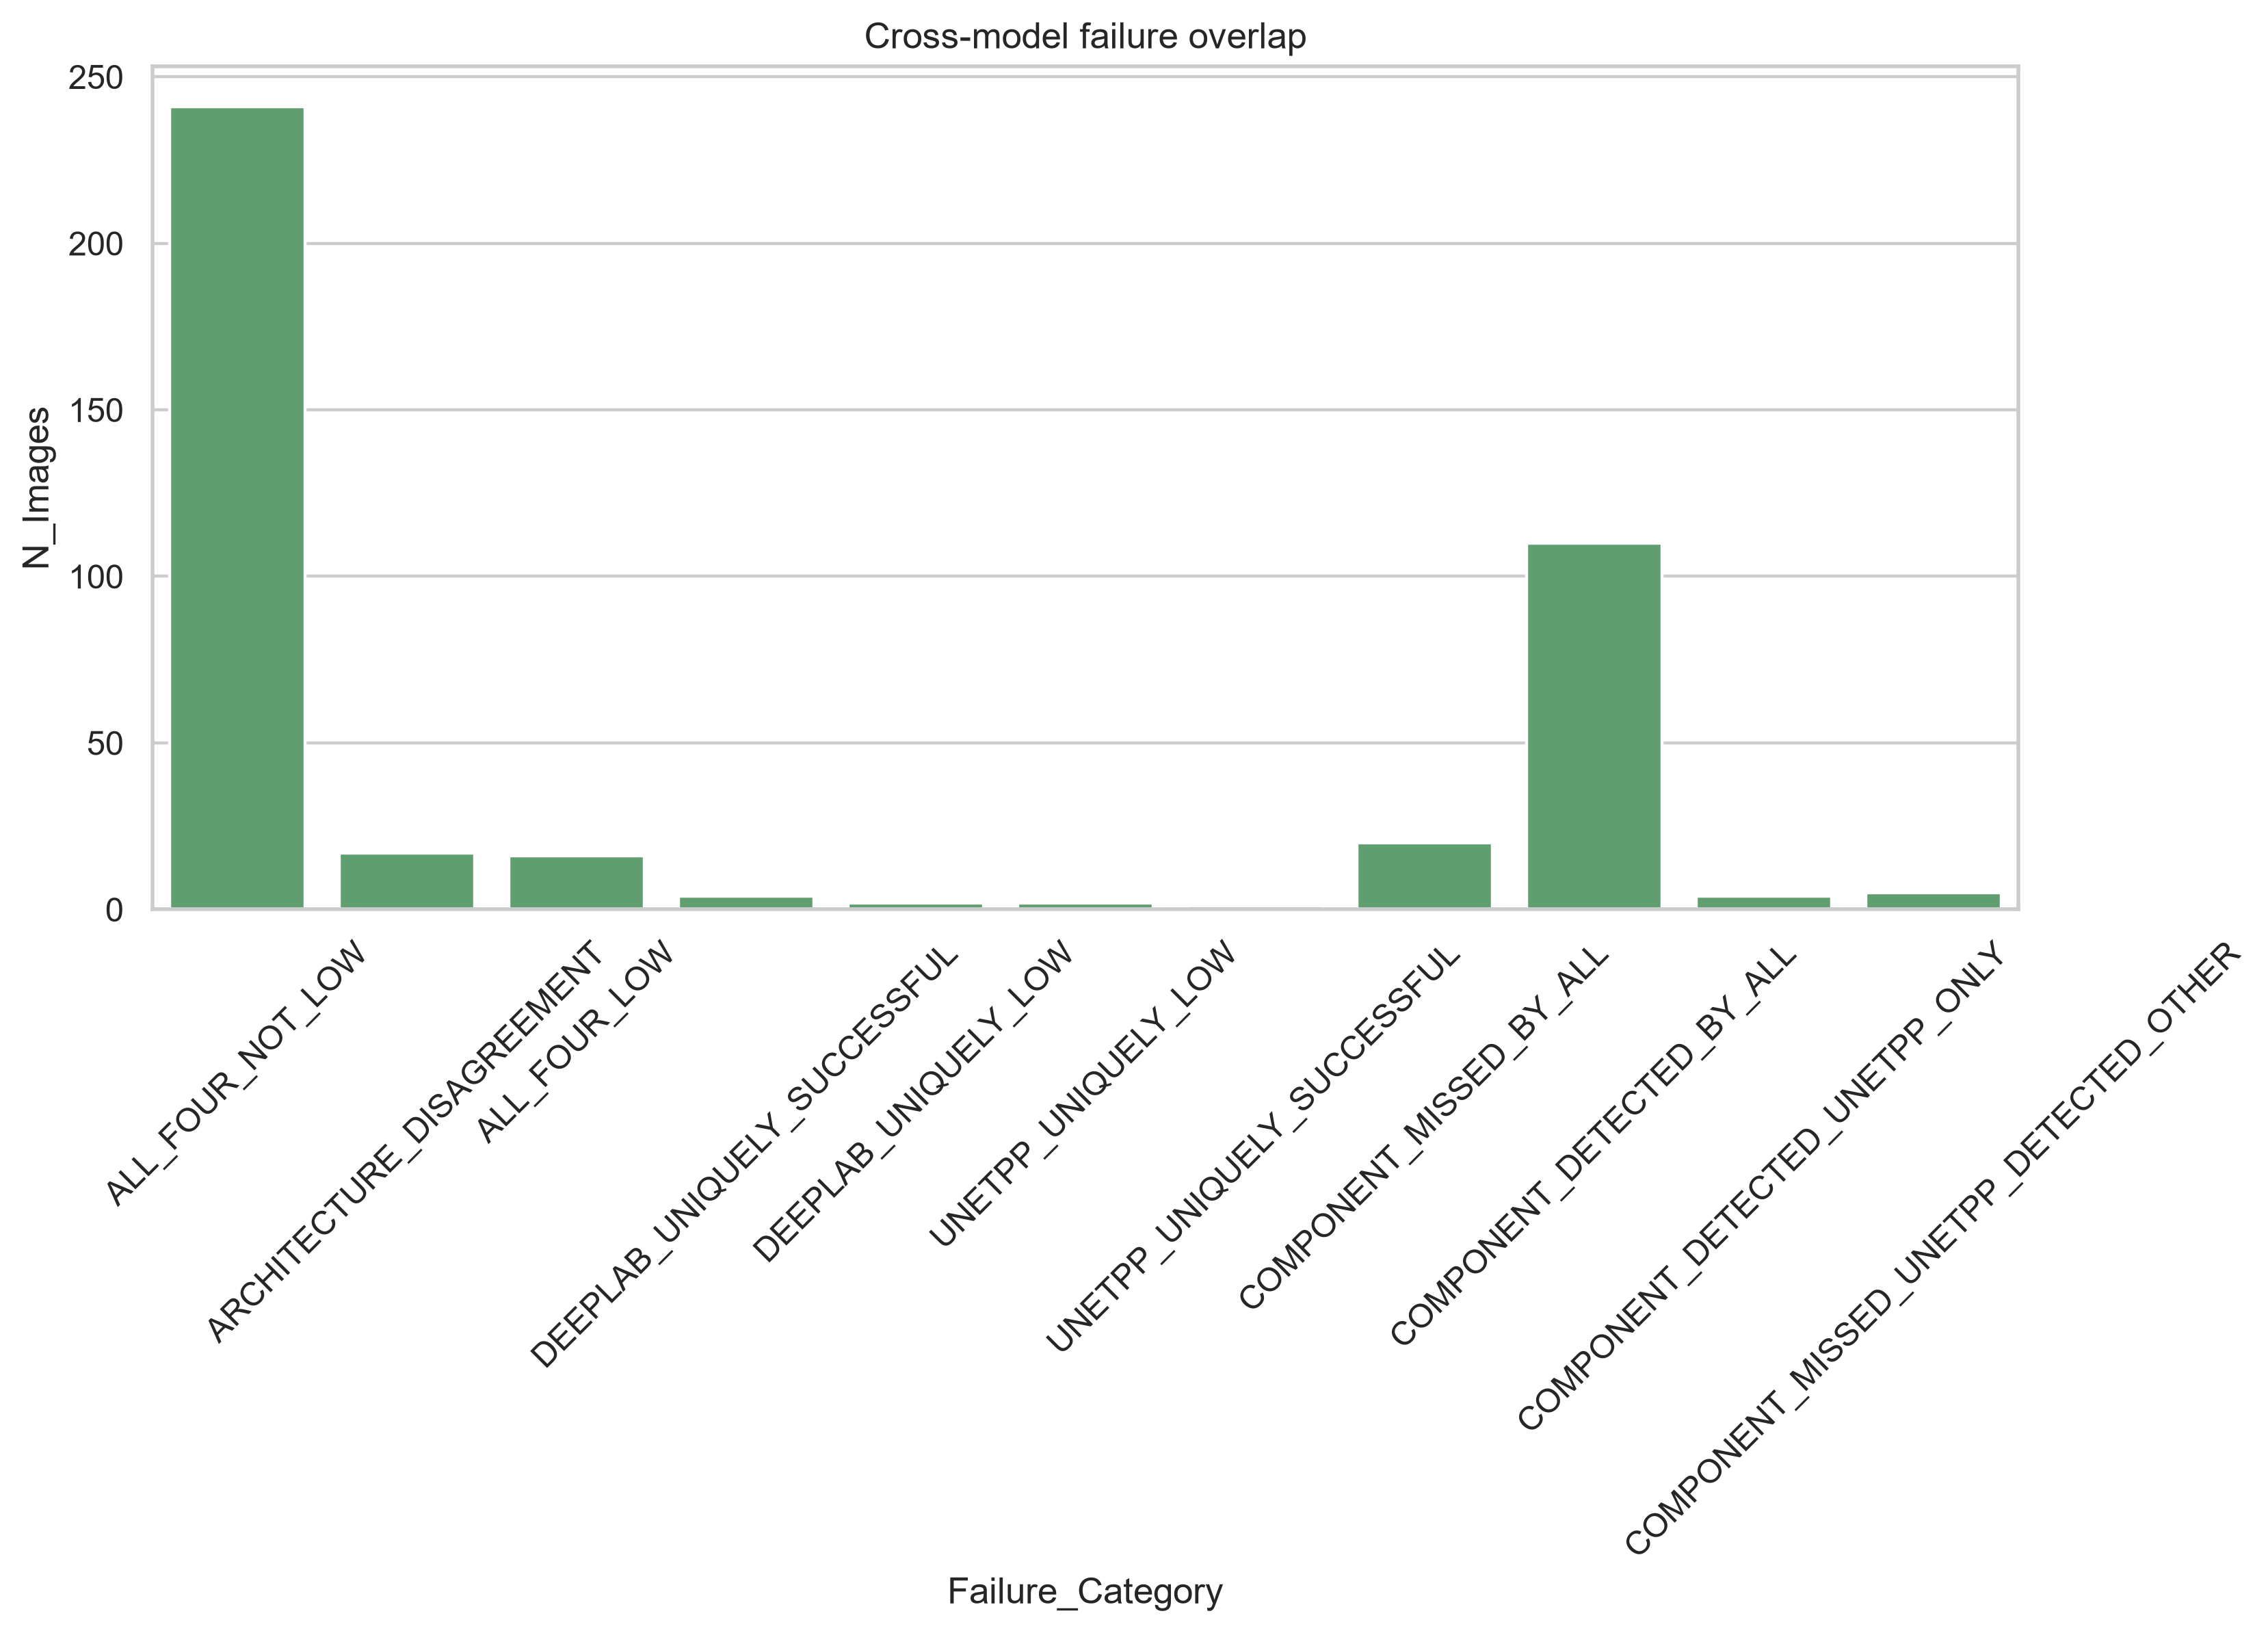

In [9]:
display(pd.read_csv(T/'phase11_cross_model_failure_overlap.csv'))
display(Image(filename=str(F/'phase11_cross_model_failure_overlap.png'),width=950))

## Patient-level clustering

In [10]:
patients=pd.read_csv(T/'phase11_kub_failure_by_patient.csv'); display(patients.sort_values(['missed_original_components','worst_dice'],ascending=[False,True]).head(20)); print(f'VAL patients: {len(patients)}')

,patient_id,N_images,mean_dice,median_dice,worst_dice,empty_prediction_count,FP_eval_components,original_components,detected_original_components,missed_original_components
84,patient-00578,3,0.528610,0.744681,2.758925e-12,1,2,4,2,2
83,patient-00570,3,0.461393,0.656093,1.234568e-09,1,4,4,2,2
27,patient-00115,3,0.587811,0.855258,1.265823e-09,1,1,4,2,2
109,patient-01714,3,0.492432,0.617928,2.272727e-09,1,20,4,2,2
24,patient-00107,3,0.515559,0.732867,9.090909e-09,1,4,4,2,2
65,patient-00401,2,0.436802,0.436802,2.881844e-10,0,5,2,1,1
54,patient-00365,2,0.457866,0.457866,3.745318e-10,0,6,2,1,1
99,patient-01257,2,0.403272,0.403272,9.708738e-10,0,1,2,1,1
94,patient-00676,2,0.449901,0.449901,1.886793e-09,0,13,2,1,1
16,patient-00053,2,0.343634,0.343634,4.166667e-09,1,5,2,1,1


VAL patients: 111


## Reproducible failure taxonomy

,Failure_Type,Count,Rate
0,EMPTY_PREDICTION,8,0.028269
1,LOW_DICE_DECILE,29,0.102473
2,HIGH_HD95_DECILE,28,0.098940
3,HIGH_FP_DECILE,39,0.137809
4,MISSED_TINY_COMPONENT,14,0.049470
5,MISSED_SMALL_COMPONENT,3,0.010601
6,PARTIAL_MULTI_COMPONENT_DETECTION,10,0.035336
7,COMPLETE_MULTI_COMPONENT_MISS,4,0.014134
8,MISSED_TINY_ORIGINAL_COMPONENT,16,0.219178
9,MISSED_SMALL_ORIGINAL_COMPONENT,4,0.137931


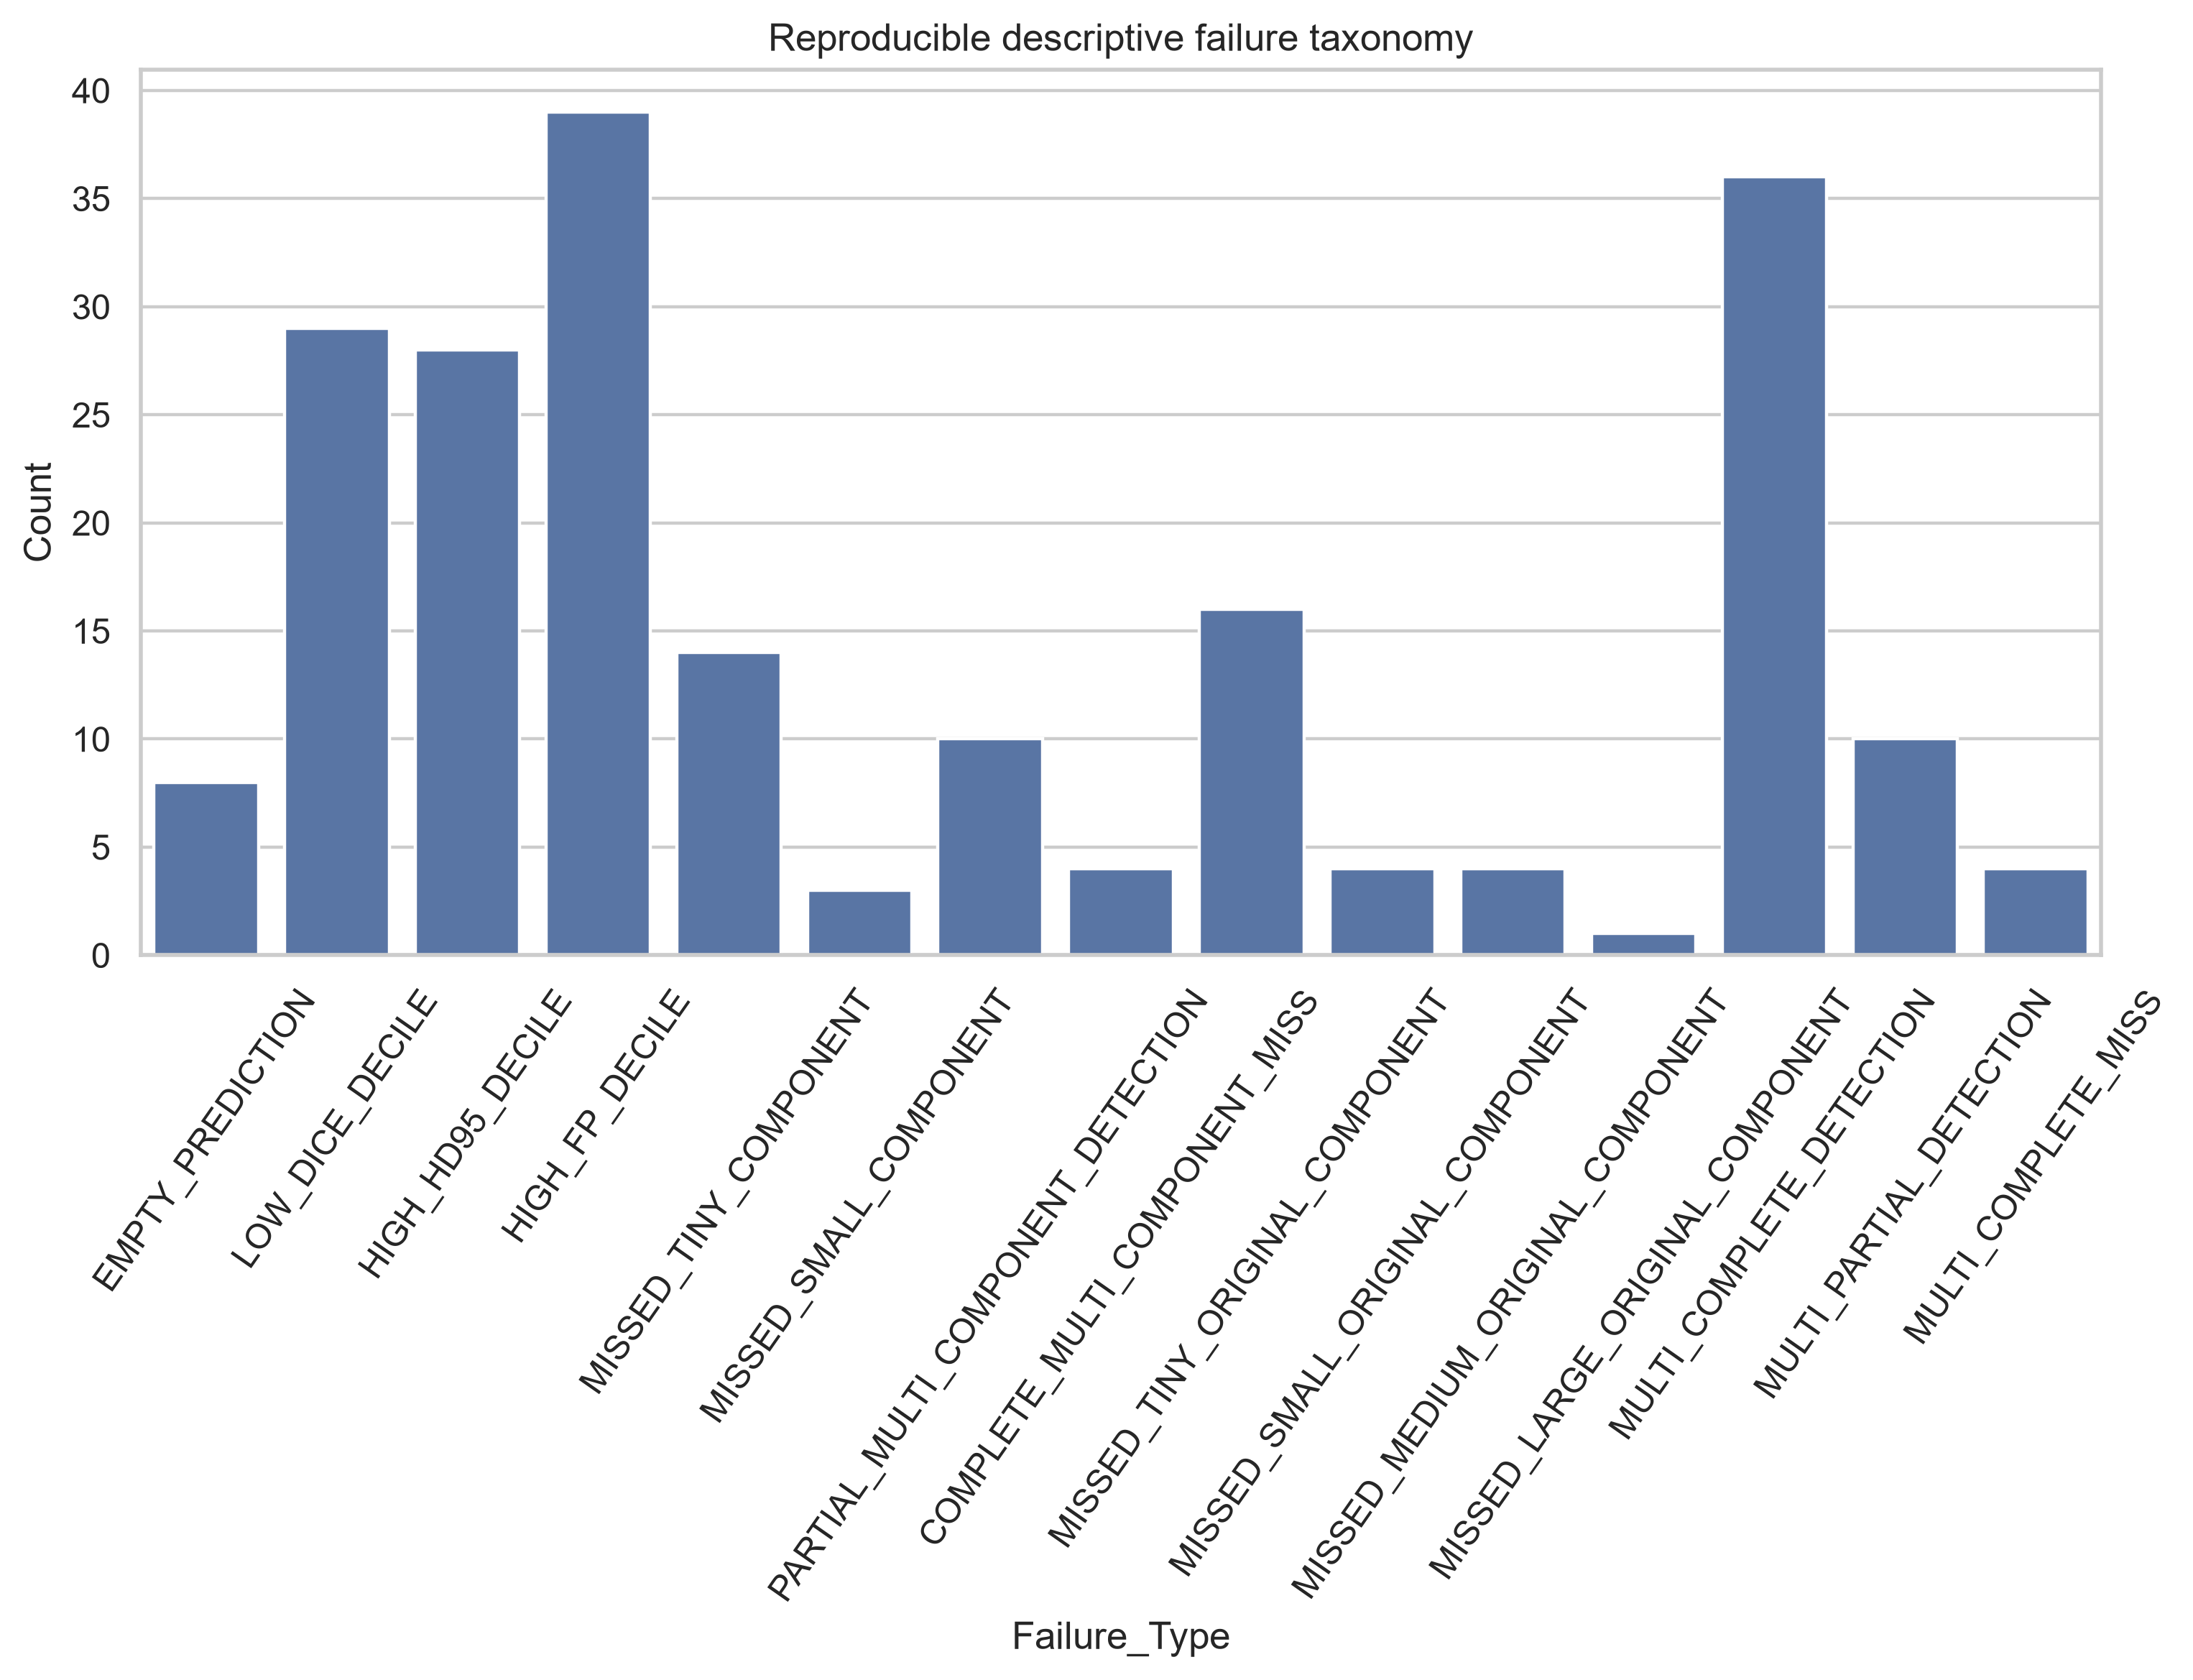

In [11]:
display(pd.read_csv(T/'phase11_kub_failure_summary.csv'))
display(Image(filename=str(F/'phase11_failure_taxonomy_counts.png'),width=1050))

## Deterministic UNet++ failure panel

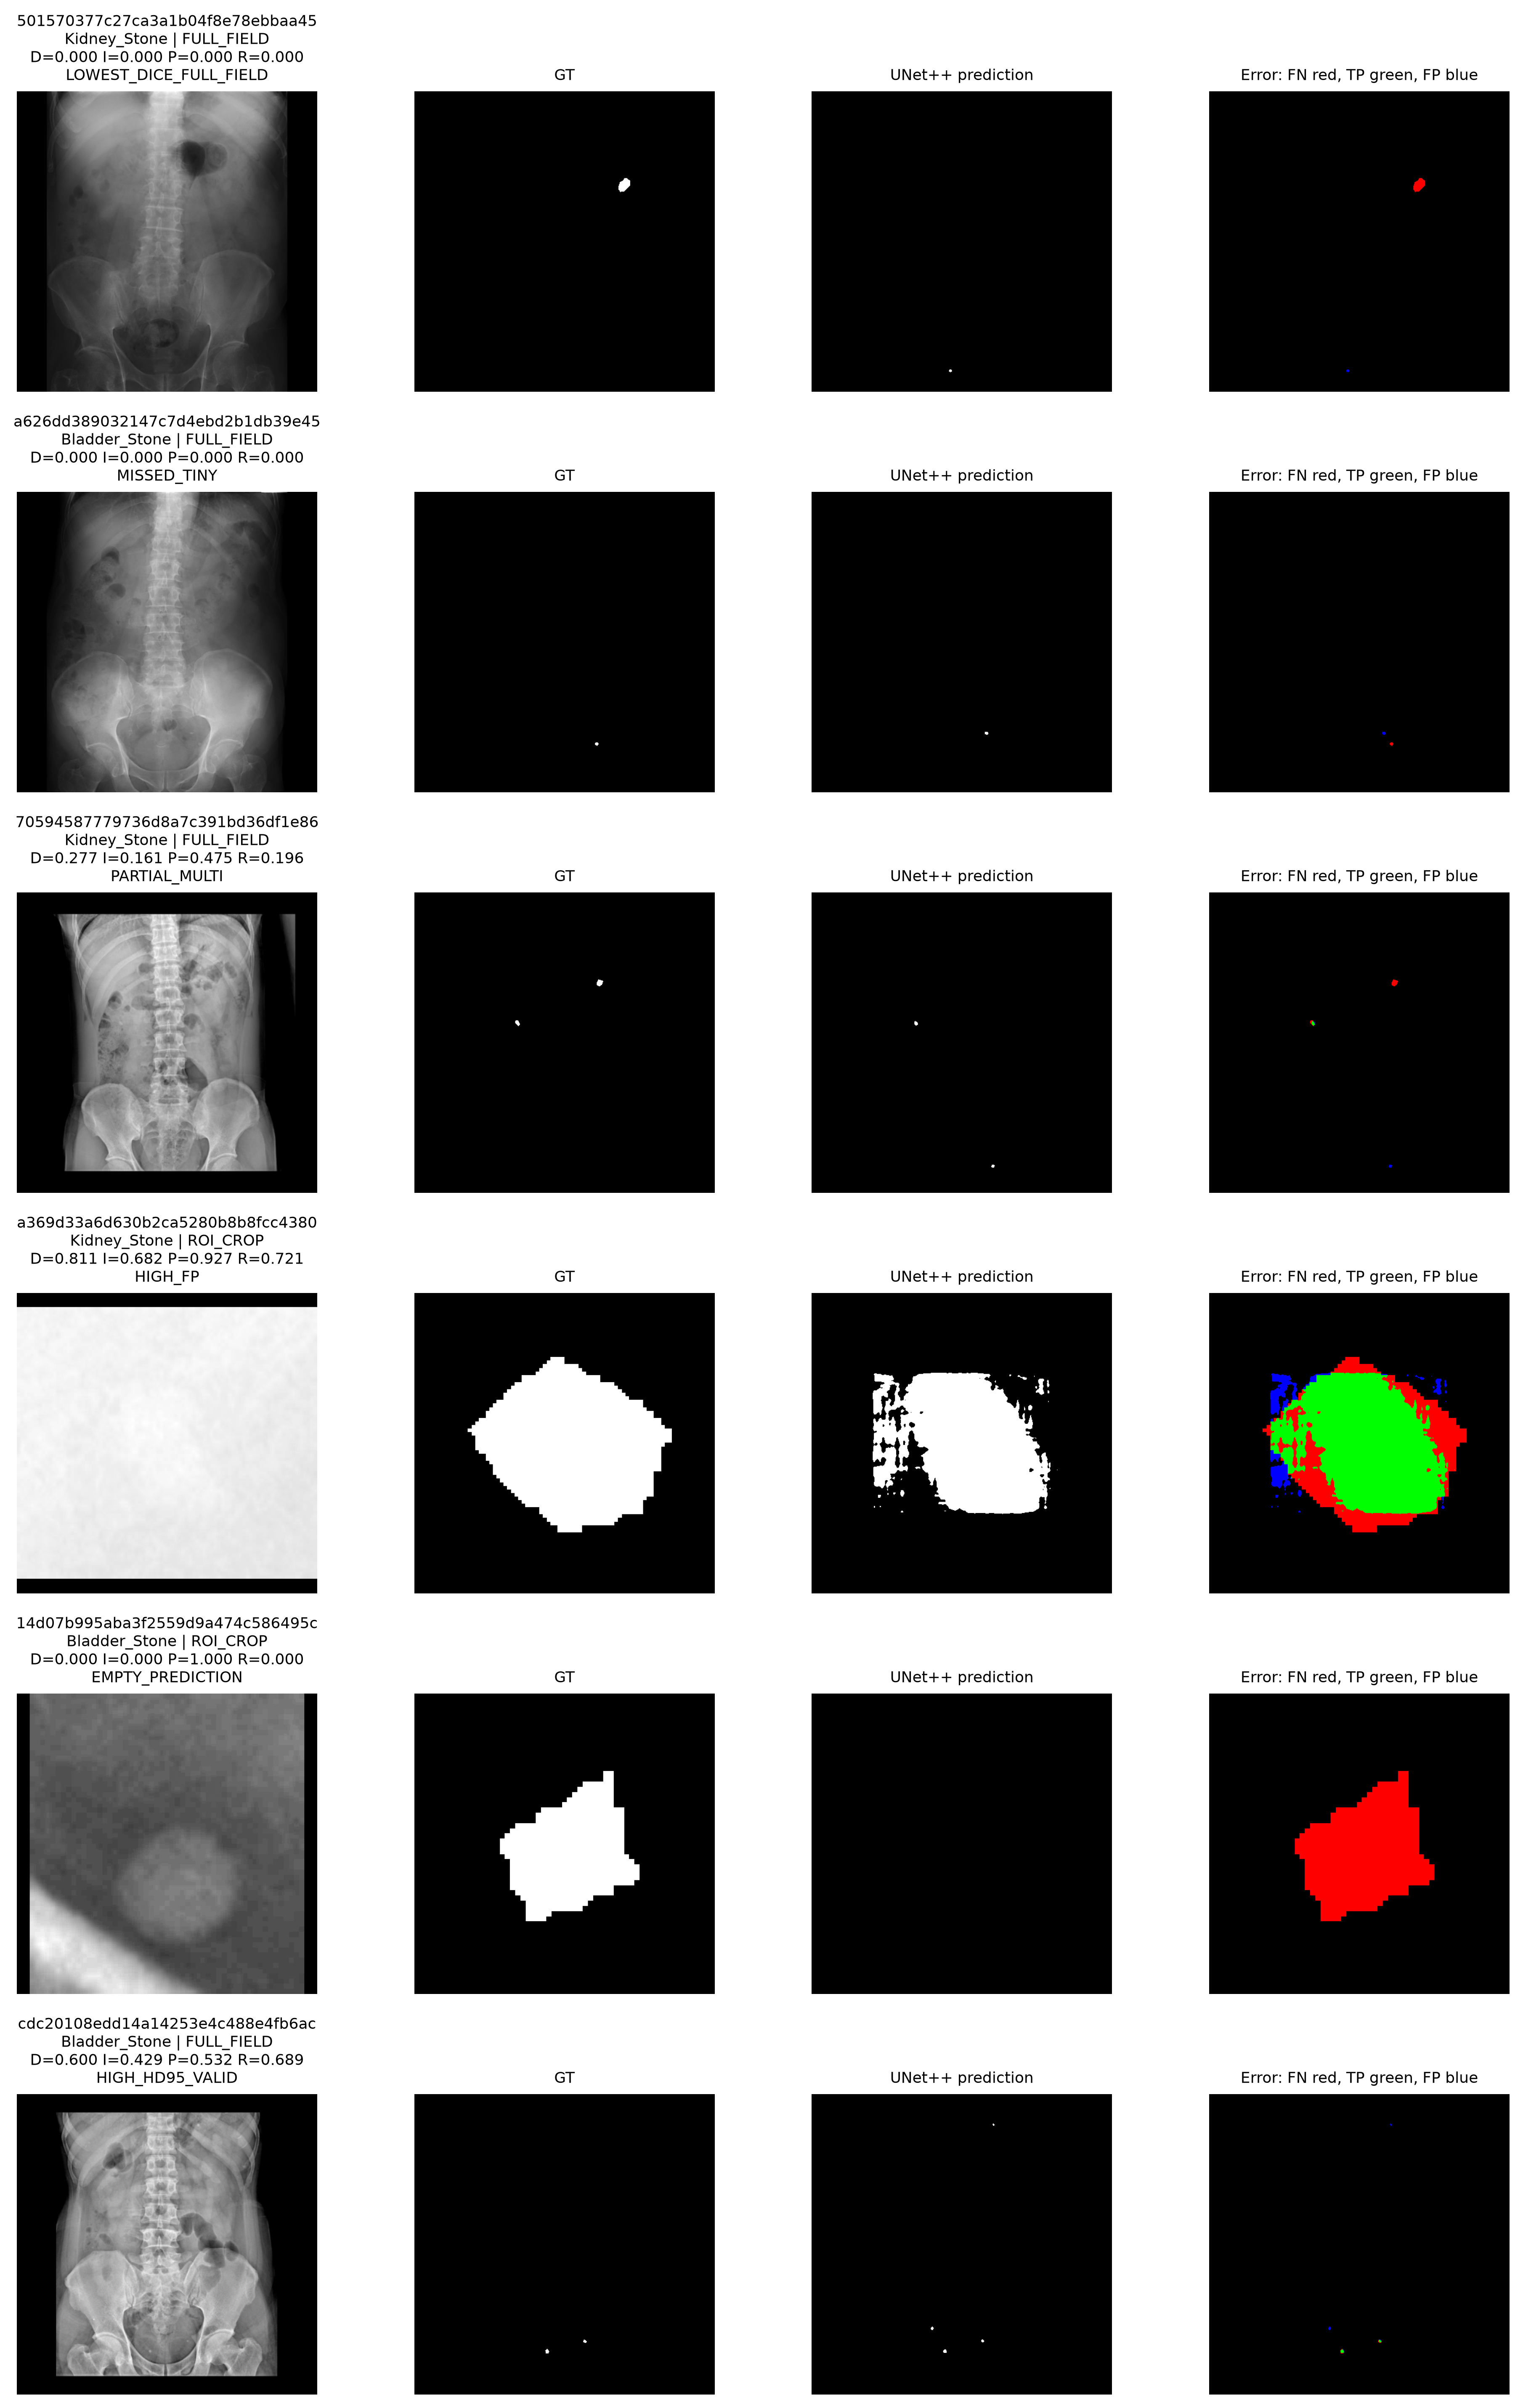

In [12]:
display(Image(filename=str(Q/'phase11_unetpp_failure_panel.png'),width=1200))

## Same-sample cross-model hard-case panel

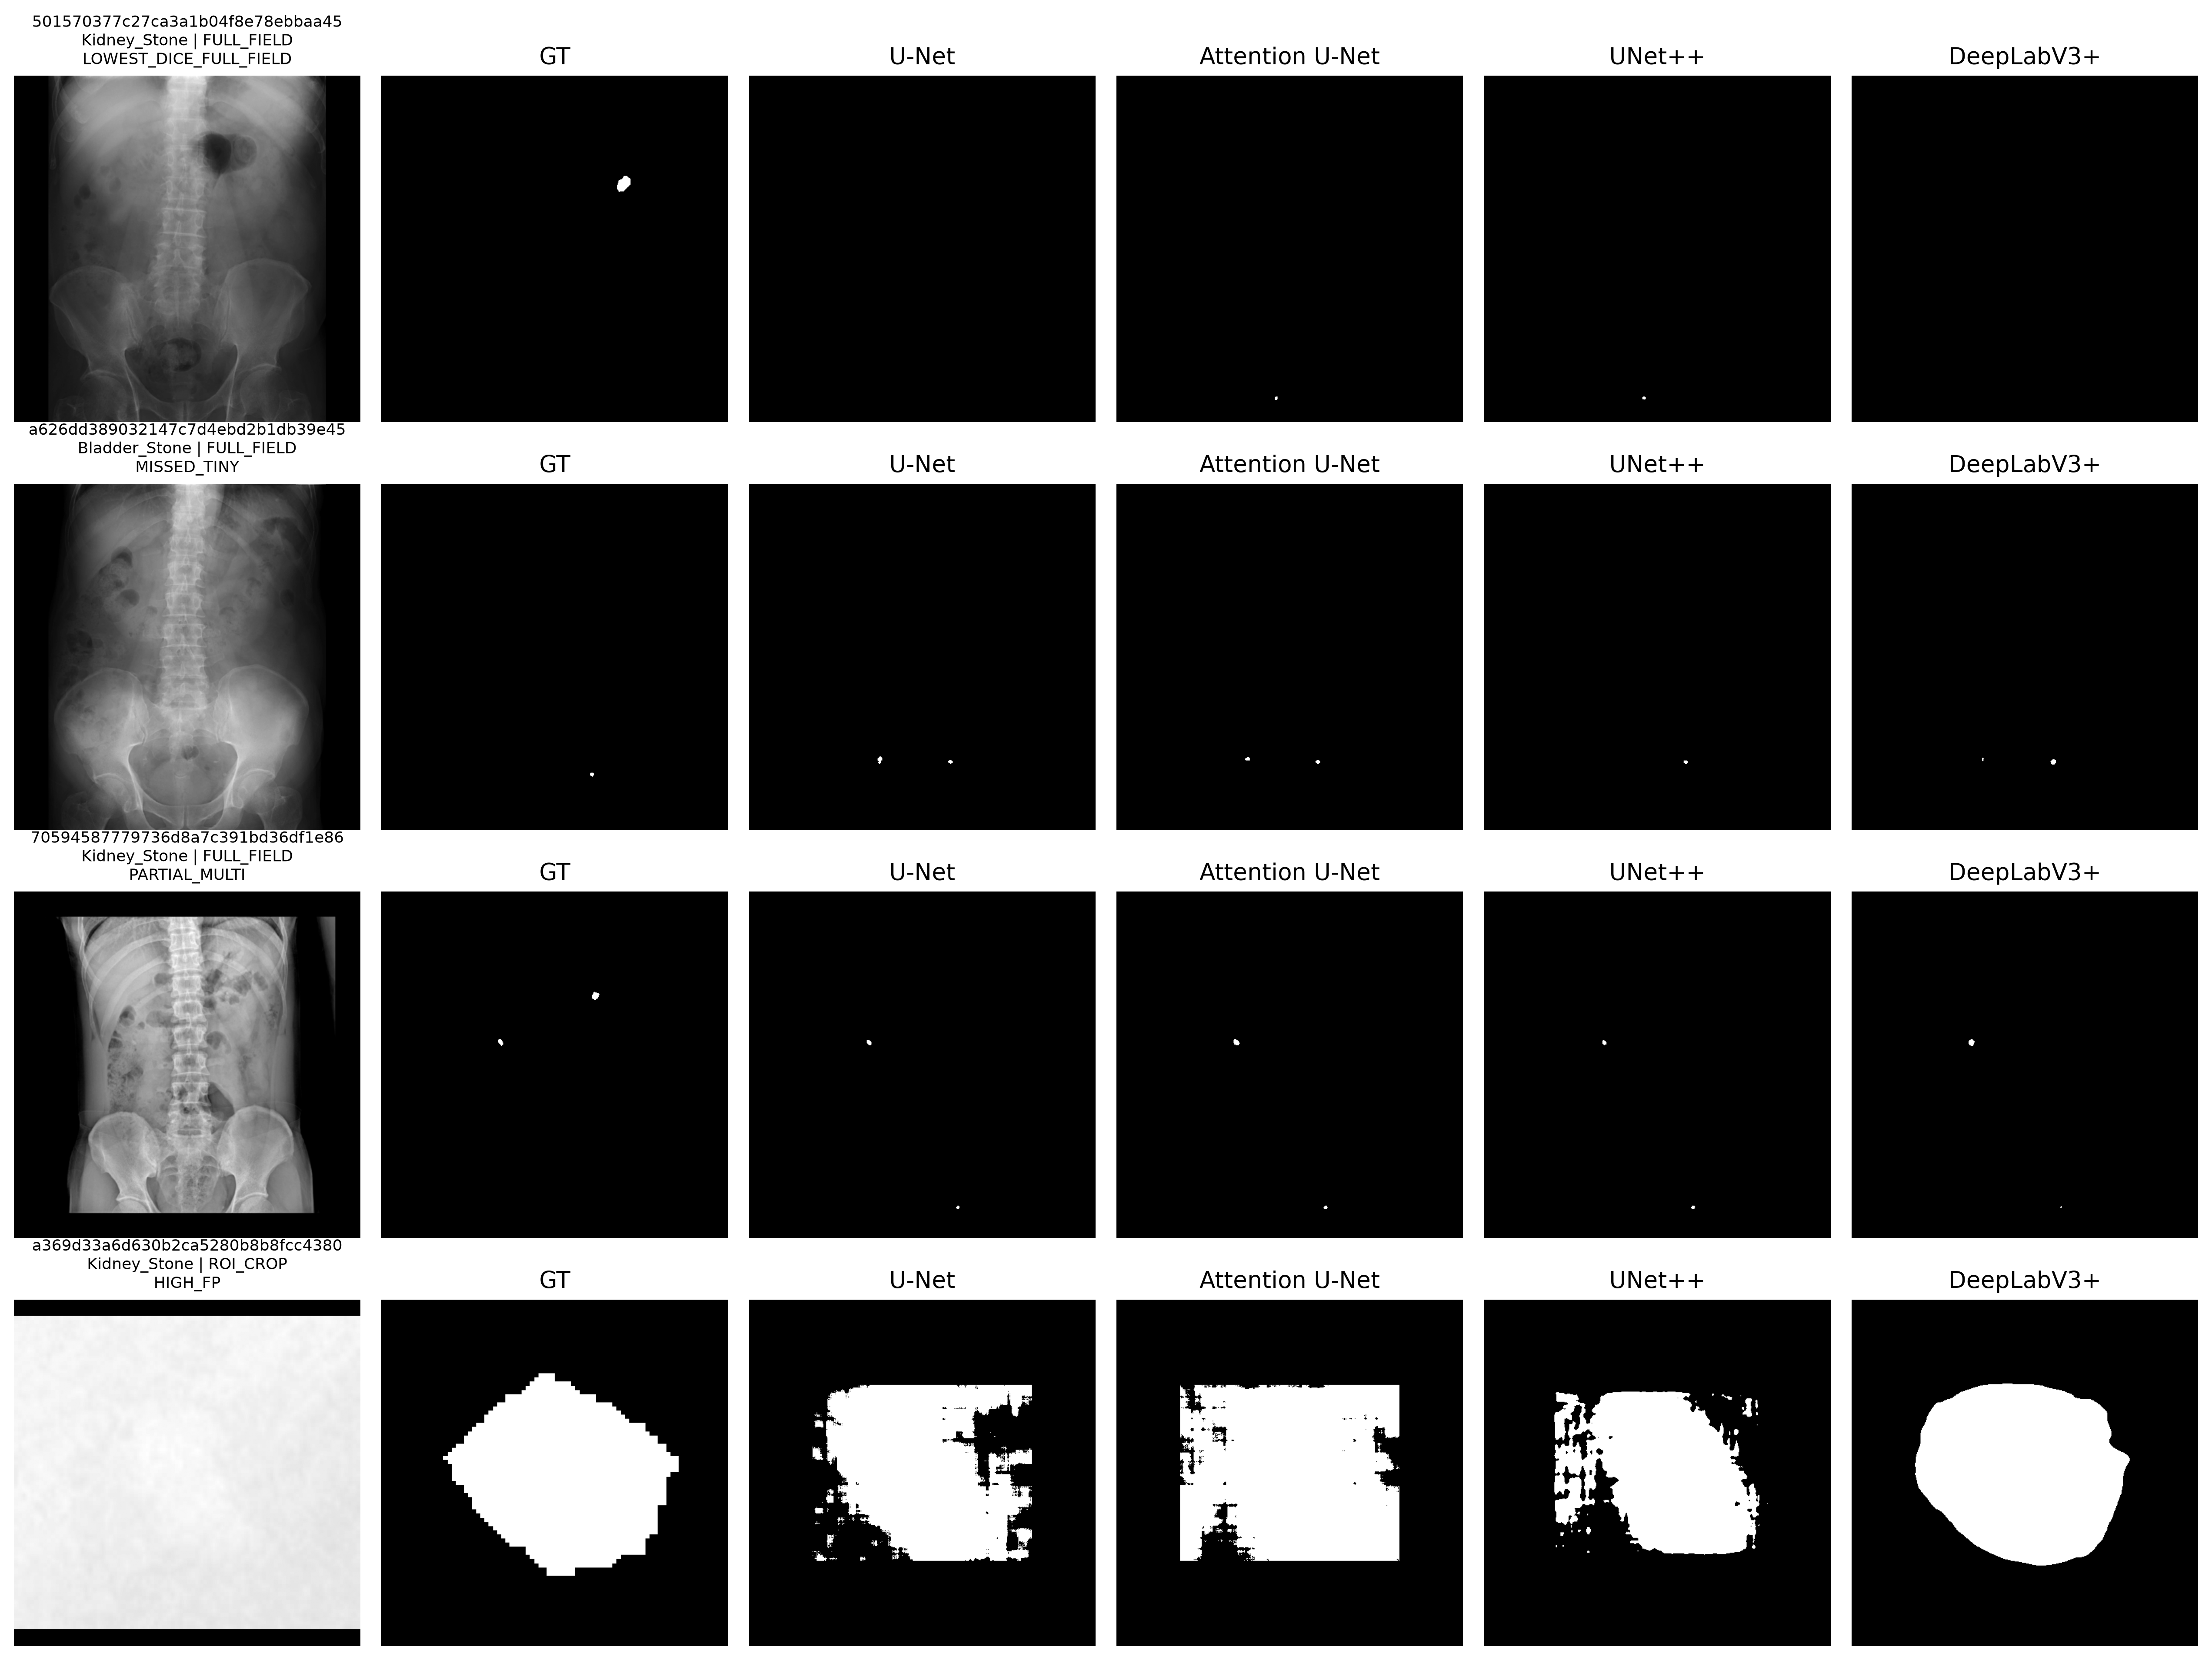

In [13]:
display(Image(filename=str(Q/'phase11_cross_model_hard_case_panel.png'),width=1200))

## Phase-12 motivation

FULL_FIELD performance remains materially below ROI_CROP performance, residual TINY/SMALL misses persist, and multi-component partial/complete misses remain. These patterns provide evidence to **test whether increased effective local resolution can recover missed targets** using an Oracle ROI/zoom upper-bound study. They do not establish that ROI will solve them.

## Limitations and phase control

Single seed and one VAL split; descriptive quantiles only; no significance or deployment claims. Original-space size identity is distinct from 512×512 evaluation-space object counts. **TEST NOT ACCESSED. Phase 12 was not executed. STOP.**